# HMM Macro Regime Detection

<a href="https://colab.research.google.com/github/SebastianIWright/hmm-macro-regime-detection/blob/main/macro_regime_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A 4-state Hidden Markov Model on FRED macro data that labels each month as Expansion, Stagflation, Recession, or Recovery, then uses those regimes to drive a multi-asset allocation. Tested with a walk-forward backtest to remove look-ahead bias.

**Setup:** add a free FRED API key as a Colab secret named `FRED_API_KEY`, then run all cells.

By Sebastian Wright · University of Florida

In [1]:
# ── Colab Installation Block ──────────────────────────
!pip install hmmlearn fredapi tabulate -q

# Verify installation
import subprocess, sys
packages = ['hmmlearn', 'fredapi', 'tabulate']
for pkg in packages:
    result = subprocess.run([sys.executable, '-m', 'pip', 'show', pkg],
                            capture_output=True, text=True)
    version = [l for l in result.stdout.split('\n') if 'Version' in l]
    print(f"  ✓ {pkg}: {version[0] if version else 'installed'}")


import warnings
warnings.filterwarnings('ignore')

# ── Standard Library ──────────────────────────────────────────────────────────
import os
import json
from datetime import datetime
from typing import Dict, List, Tuple, Optional

# ── Scientific Computing ──────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import norm, multivariate_normal
import statsmodels.api as sm

# ── Machine Learning ──────────────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, classification_report,
                              silhouette_score, adjusted_rand_score)
from sklearn.model_selection import TimeSeriesSplit
from hmmlearn.hmm import GaussianHMM

# ── Visualization ─────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates
import seaborn as sns
try:
    from IPython.display import display, HTML
except ImportError:
    pass  # Not required — only used in Colab for rich table rendering

# ── Global Configuration ──────────────────────────────────────────────────────
np.random.seed(42)
plt.rcParams.update({
    'figure.facecolor':  '#0d1117',   # GitHub dark background
    'axes.facecolor':    '#0d1117',
    'axes.edgecolor':    '#30363d',
    'axes.labelcolor':   '#e6edf3',
    'axes.titlecolor':   '#e6edf3',
    'xtick.color':       '#8b949e',
    'ytick.color':       '#8b949e',
    'text.color':        '#e6edf3',
    'grid.color':        '#21262d',
    'grid.alpha':        0.6,
    'grid.linewidth':    0.5,
    'font.family':       'monospace',
    'axes.titlesize':    13,
    'axes.labelsize':    11,
    'legend.fontsize':   10,
    'figure.titlesize':  15,
})

# ── Color Palette ─────────────────────────────────────────────────────────────
PALETTE = {
    'Expansion':    '#3fb950',   # Green
    'Stagflation':  '#e3b341',   # Amber
    'Recession':    '#f85149',   # Red
    'Recovery':     '#388bfd',   # Blue
}
PALETTE_LIST = list(PALETTE.values())

print("=" * 70)
print("  MACRO REGIME DETECTION MODEL  |  Google Colab Environment")
print("=" * 70)
print(f"  NumPy:        {np.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  Scikit-learn: {__import__('sklearn').__version__}")
print(f"  HMMlearn:     {__import__('hmmlearn').__version__}")
print(f"  Matplotlib:   {matplotlib.__version__}")
print("=" * 70)
print("  ✓ All libraries loaded successfully. Ready to build.")
print("=" * 70)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 4.4 MB/s eta 0:00:00
  ✓ hmmlearn: Version: 0.3.3
  ✓ fredapi: Version: 0.5.2
  ✓ tabulate: Version: 0.9.0
  MACRO REGIME DETECTION MODEL  |  Google Colab Environment
  NumPy:        2.0.2
  Pandas:       2.2.2
  Scikit-learn: 1.6.1
  HMMlearn:     0.3.3
  Matplotlib:   3.10.0
  ✓ All libraries loaded successfully. Ready to build.


## 1. Constants and Configuration

Central configuration hub. All tunable parameters live here.

In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
# CONSTANTS & CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Central configuration hub. All tunable parameters live here.
# Change N_STATES, START_DATE, or HMM hyperparameters without touching model code.

# ── Date Range ────────────────────────────────────────────────────────────────
START_DATE   = '1990-01-01'
END_DATE     = '2024-12-31'
FREQ         = 'MS'          # Month-Start frequency (matches FRED monthly release)

# ── Model Configuration ───────────────────────────────────────────────────────
N_STATES          = 4        # Expansion, Stagflation, Recession, Recovery
N_PCA_COMPONENTS  = 4        # PCA dimensions fed into HMM
HMM_ITER          = 500      # Max EM iterations
HMM_COVARIANCE    = 'full'   # Full covariance matrix (vs. 'diag' or 'tied')
HMM_N_INIT        = 10       # Number of random restarts to find best HMM

# ── Asset Allocation Strategies ───────────────────────────────────────────────
# Regime-Aware Portfolio weights: [Equities, Bonds, Gold, Commodities]
REGIME_WEIGHTS = {
    'Expansion':   [0.60, 0.25, 0.05, 0.10],
    'Recovery':    [0.70, 0.20, 0.05, 0.05],
    'Recession':   [0.10, 0.60, 0.20, 0.10],
    'Stagflation': [0.10, 0.15, 0.35, 0.40],
}
BENCHMARK_WEIGHTS = [0.60, 0.40, 0.00, 0.00]  # Classic 60/40

# ── Macro Feature Labels ──────────────────────────────────────────────────────
MACRO_FEATURES = [
    'gdp_growth',       # Real GDP growth (%, QoQ annualized)
    'cpi_yoy',          # CPI year-over-year inflation (%)
    'unemployment',     # Unemployment rate (%)
    'ism_mfg',          # ISM Manufacturing PMI (> 50 = expansion)
    'yield_spread',     # 10Y - 2Y Treasury yield spread (%)
    'fed_rate',         # Federal Funds Rate (%)
    'credit_spread',    # High-yield OAS spread (%)
    'consumer_conf',    # Conference Board Consumer Confidence Index
]

ASSET_NAMES   = ['Equities', 'Bonds', 'Gold', 'Commodities']
REGIME_NAMES  = ['Expansion', 'Stagflation', 'Recession', 'Recovery']

# ── FRED Series Codes (for production deployment) ─────────────────────────────
FRED_SERIES = {
    'gdp_growth':   'A191RL1Q225SBEA',  # Real GDP growth rate, quarterly
    'cpi_yoy':      'CPIAUCSL',          # CPI All Items, monthly
    'unemployment': 'UNRATE',            # Civilian Unemployment Rate
    'ism_mfg':      'MANEMP',            # ISM Manufacturing (approx via employment)
    'yield_spread': 'T10Y2Y',            # 10-Year minus 2-Year Treasury
    'fed_rate':     'FEDFUNDS',          # Effective Federal Funds Rate
    'credit_spread':'BAMLH0A0HYM2',     # ICE BofA US High Yield OAS
    'consumer_conf':'UMCSENT',           # University of Michigan Sentiment
}

# ── Yahoo Finance Tickers (for production deployment) ─────────────────────────
ASSET_TICKERS = {
    'Equities':    'SPY',   # SPDR S&P 500 ETF
    'Bonds':       'TLT',   # iShares 20+ Year Treasury Bond ETF
    'Gold':        'GLD',   # SPDR Gold Shares ETF
    'Commodities': 'DJP',   # iPath Bloomberg Commodity Index ETN
}

print("✓ Configuration loaded.")
print(f"  Date range:     {START_DATE} → {END_DATE}")
print(f"  HMM states:     {N_STATES} ({', '.join(REGIME_NAMES)})")
print(f"  PCA components: {N_PCA_COMPONENTS}")
print(f"  Macro features: {len(MACRO_FEATURES)}")
print(f"  Asset classes:  {len(ASSET_NAMES)}")

regime_map = {0: 'Expansion', 1: 'Stagflation', 2: 'Recession', 3: 'Recovery'}

✓ Configuration loaded.
  Date range:     1990-01-01 → 2024-12-31
  HMM states:     4 (Expansion, Stagflation, Recession, Recovery)
  PCA components: 4
  Macro features: 8
  Asset classes:  4


## 2. Data Collection Pipeline (Live FRED + Yfinance)

In [3]:
# ═══════════════════════════════════════════════════════════════════════════════
# DATA COLLECTION PIPELINE (LIVE FRED + YFINANCE)
# ═══════════════════════════════════════════════════════════════════════════════

from fredapi import Fred
import yfinance as yf

import os
try:
    from google.colab import userdata
    FRED_API_KEY = userdata.get('FRED_API_KEY')
except Exception:
    FRED_API_KEY = os.environ.get('FRED_API_KEY')

# ── Fetch macro data from FRED ────────────────────────────────────────────────
def fetch_macro_data():
    fred = Fred(api_key=FRED_API_KEY)
    data = {}
    for name, series_id in FRED_SERIES.items():
        try:
            raw = fred.get_series(series_id,
                                   observation_start=START_DATE,
                                   observation_end=END_DATE)
            raw = raw.resample('MS').last().interpolate(method='time')
            if name == 'cpi_yoy':
                raw = raw.pct_change(12) * 100
            data[name] = raw
            print(f"  ✓ {name} ({series_id}): {len(raw)} obs")
        except Exception as e:
            print(f"  ✗ FAILED {name} ({series_id}): {e}")
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index)
    return df  # do NOT dropna here — we'll handle sparse columns first

# ── Fetch asset returns from Yahoo Finance ────────────────────────────────────
def fetch_asset_returns():
    tickers = {
        'equity_ret': 'SPY',
        'bond_ret':   'TLT',
        'gold_ret':   'GLD',
        'cmdty_ret':  'GSG',
    }
    data = {}
    for col, ticker in tickers.items():
        try:
            raw = yf.download(ticker,
                               start=START_DATE,
                               end=END_DATE,
                               progress=False,
                               auto_adjust=True)
            if isinstance(raw.columns, pd.MultiIndex):
                prices = raw[('Close', ticker)]
            else:
                prices = raw['Close']
            monthly = prices.resample('MS').last().pct_change() * 100
            data[col] = monthly
            print(f"  ✓ {ticker}: {len(monthly)} months")
        except Exception as e:
            print(f"  ✗ FAILED {ticker}: {e}")
    df = pd.DataFrame(data)
    df.index = pd.to_datetime(df.index)
    return df.dropna()

# ── Run fetches ───────────────────────────────────────────────────────────────
print("Fetching FRED macro data...")
macro_df = fetch_macro_data()

print("\nFetching asset returns...")
asset_df = fetch_asset_returns()

# ── Drop any columns with fewer than 100 valid observations ───────────────────
# This catches credit_spread (BAMLH0A0HYM2) which only returned 19 obs
print("\nChecking column coverage:")
cols_to_drop = []
for col in macro_df.columns:
    n_valid = macro_df[col].notna().sum()
    if n_valid < 100:
        cols_to_drop.append(col)
        print(f"  ✗ Dropping '{col}': only {n_valid} valid obs")
    else:
        print(f"  ✓ '{col}': {n_valid} valid obs")

if cols_to_drop:
    macro_df = macro_df.drop(columns=cols_to_drop)
    for col in cols_to_drop:
        if col in MACRO_FEATURES:
            MACRO_FEATURES.remove(col)
    print(f"\n  Updated MACRO_FEATURES ({len(MACRO_FEATURES)} features):")
    print(f"  {MACRO_FEATURES}")

# ── Now safe to dropna on macro ───────────────────────────────────────────────
macro_df = macro_df.dropna()

# ── Align both DataFrames ─────────────────────────────────────────────────────
macro_df, asset_df = macro_df.align(asset_df, join='inner', axis=0)

# ── Final check ───────────────────────────────────────────────────────────────
print(f"\n  macro_df: {len(macro_df)} months")
print(f"  asset_df: {len(asset_df)} months")
print(f"  Overlap:  {macro_df.index[0].strftime('%b %Y')} → "
      f"{macro_df.index[-1].strftime('%b %Y')}")

if len(macro_df) < 100:
    raise ValueError(
        f"Still only {len(macro_df)} months after cleanup. "
        f"Shortest series is the bottleneck — check obs counts above."
    )

# ── Add placeholder regime column ─────────────────────────────────────────────
macro_df['true_regime'] = 0
asset_df['true_regime'] = 0

print(f"\n✓ Data ready for feature engineering.")
print(f"  Macro columns: {[c for c in macro_df.columns if c != 'true_regime']}")
print(f"  Asset columns: {[c for c in asset_df.columns if c != 'true_regime']}")

Fetching FRED macro data...
  ✓ gdp_growth (A191RL1Q225SBEA): 418 obs
  ✓ cpi_yoy (CPIAUCSL): 420 obs
  ✓ unemployment (UNRATE): 420 obs
  ✓ ism_mfg (MANEMP): 420 obs
  ✓ yield_spread (T10Y2Y): 420 obs
  ✓ fed_rate (FEDFUNDS): 420 obs
  ✓ credit_spread (BAMLH0A0HYM2): 19 obs
  ✓ consumer_conf (UMCSENT): 420 obs

Fetching asset returns...
  ✓ SPY: 384 months
  ✓ TLT: 270 months
  ✓ GLD: 242 months
  ✓ GSG: 222 months

Checking column coverage:
  ✓ 'gdp_growth': 418 valid obs
  ✓ 'cpi_yoy': 408 valid obs
  ✓ 'unemployment': 420 valid obs
  ✓ 'ism_mfg': 420 valid obs
  ✓ 'yield_spread': 420 valid obs
  ✓ 'fed_rate': 420 valid obs
  ✗ Dropping 'credit_spread': only 19 valid obs
  ✓ 'consumer_conf': 420 valid obs

  Updated MACRO_FEATURES (7 features):
  ['gdp_growth', 'cpi_yoy', 'unemployment', 'ism_mfg', 'yield_spread', 'fed_rate', 'consumer_conf']

  macro_df: 219 months
  asset_df: 219 months
  Overlap:  Aug 2006 → Oct 2024

✓ Data ready for feature engineering.
  Macro columns: ['gdp_g

## 3. Data Cleaning and Feature Engineering

Clean macro data, engineer additional features, apply PCA for

In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# DATA CLEANING & FEATURE ENGINEERING
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Clean macro data, engineer additional features, apply PCA for
# dimensionality reduction before feeding into the HMM.
#
# INSTITUTIONAL CONTEXT: Real macro data has missing releases, revisions,
# and outliers. This pipeline handles all of that systematically.

class FeatureEngineer:
    """
    Macro feature engineering pipeline.

    Applies:
        1. Outlier detection and winsorization (Grubbs test threshold 3σ)
        2. Missing value imputation (forward-fill, then linear interpolation)
        3. Derived feature construction (momentum, acceleration)
        4. Cross-sectional standardization (Z-score normalization)
        5. PCA dimensionality reduction with explained variance analysis
    """

    def __init__(self, n_pca: int = 4, winsor_threshold: float = 3.0):
        self.n_pca = n_pca
        self.winsor_threshold = winsor_threshold
        self.scaler = StandardScaler()
        self.pca = PCA(n_components=n_pca, random_state=42)
        self.feature_cols = MACRO_FEATURES.copy()

    def _detect_outliers(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Winsorize extreme values at ±winsor_threshold standard deviations.
        This prevents single-observation events (e.g., COVID shock) from
        destabilizing the HMM's EM optimization.
        """
        df_clean = df.copy()
        outlier_log = {}
        for col in self.feature_cols:
            mu = df_clean[col].mean()
            sigma = df_clean[col].std()
            lower = mu - self.winsor_threshold * sigma
            upper = mu + self.winsor_threshold * sigma
            n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
            if n_outliers > 0:
                outlier_log[col] = n_outliers
            df_clean[col] = df_clean[col].clip(lower, upper)
        if outlier_log:
            print(f"  Winsorized outliers: "
                  f"{', '.join(f'{k}({v})' for k,v in outlier_log.items())}")
        return df_clean

    def _impute_missing(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Impute missing values using forward-fill (appropriate for macro data
        since FRED releases are periodic, not real-time) followed by linear
        interpolation for any remaining gaps.
        """
        df_imputed = df.copy()
        for col in self.feature_cols:
            n_missing = df_imputed[col].isna().sum()
            if n_missing > 0:
                print(f"  Imputed {n_missing} missing values in '{col}'")
                df_imputed[col] = (df_imputed[col]
                                   .ffill()
                                   .interpolate(method='linear', limit_direction='both'))
        return df_imputed

    def _engineer_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Engineer additional derivative features for richer regime signal:
            - Momentum (3-month change): captures rate of change, not just level
            - Acceleration (change of change): captures turning points early
        These features are important because regimes often turn before
        indicator levels cross historical thresholds.
        """
        df_eng = df.copy()

        # GDP acceleration: is growth picking up or slowing down?
        df_eng['gdp_momentum']     = df_eng['gdp_growth'].diff(3)
        df_eng['cpi_momentum']     = df_eng['cpi_yoy'].diff(3)
        df_eng['unemp_momentum']   = df_eng['unemployment'].diff(3)
        df_eng['ism_momentum']     = df_eng['ism_mfg'].diff(3)

        # Update feature column list to include engineered features
        self.feature_cols_extended = self.feature_cols + [
            'gdp_momentum', 'cpi_momentum', 'unemp_momentum', 'ism_momentum']

        return df_eng.dropna()

    def fit_transform(self, df: pd.DataFrame) -> Tuple[np.ndarray, pd.DataFrame]:
        """
        Full pipeline: clean → engineer → scale → PCA.

        Returns:
            X_pca:    PCA-transformed feature matrix (n_obs × n_pca)
            df_clean: Cleaned DataFrame with all engineered features
        """
        print("  Step 1: Outlier detection and winsorization...")
        df_clean = self._detect_outliers(df[self.feature_cols + ['true_regime']].copy())

        print("  Step 2: Missing value imputation...")
        df_clean = self._impute_missing(df_clean)

        print("  Step 3: Feature engineering (momentum, acceleration)...")
        df_clean = self._engineer_features(df_clean)

        print("  Step 4: StandardScaler normalization...")
        X_raw = df_clean[self.feature_cols_extended].values
        X_scaled = self.scaler.fit_transform(X_raw)

        print(f"  Step 5: PCA ({len(self.feature_cols_extended)}D → {self.n_pca}D)...")
        X_pca = self.pca.fit_transform(X_scaled)
        ev = self.pca.explained_variance_ratio_
        cumev = ev.cumsum()
        for i, (e, c) in enumerate(zip(ev, cumev)):
            print(f"    PC{i+1}: {e:.3f} variance  |  Cumulative: {c:.3f}")

        print(f"\n  ✓ Feature engineering complete:")
        print(f"    Input shape:  {df[self.feature_cols].shape}")
        print(f"    Output shape: {X_pca.shape}")
        print(f"    Variance retained: {cumev[-1]*100:.1f}%")

        self.df_clean = df_clean
        self.X_pca = X_pca
        return X_pca, df_clean

    def get_pca_loadings(self) -> pd.DataFrame:
        """Return PCA loadings table for interpretation."""
        return pd.DataFrame(
            self.pca.components_.T,
            index=self.feature_cols_extended,
            columns=[f'PC{i+1}' for i in range(self.n_pca)]
        )


# ── Run Feature Engineering ───────────────────────────────────────────────────
print("=" * 60)
print("  FEATURE ENGINEERING PIPELINE")
print("=" * 60)
fe = FeatureEngineer(n_pca=N_PCA_COMPONENTS, winsor_threshold=3.0)
X_pca, df_clean = fe.fit_transform(macro_df)

# Align asset returns to cleaned data
asset_clean = asset_df.loc[df_clean.index]

# ── PCA Loadings Analysis ─────────────────────────────────────────────────────
loadings = fe.get_pca_loadings()
print(f"\n  PCA Factor Interpretation:")
print(f"  {'Feature':20s} {'PC1':>8s} {'PC2':>8s} {'PC3':>8s} {'PC4':>8s}")
print(f"  {'─'*56}")
for feat, row in loadings.iterrows():
    vals = ''.join(f"{v:8.3f}" for v in row)
    print(f"  {feat:20s}{vals}")
print(f"\n  Interpretation:")
print(f"  PC1 (Growth factor):     Loads on GDP, ISM, Consumer Conf, Employment")
print(f"  PC2 (Inflation factor):  Loads on CPI, Fed Rate, Credit Spread")
print(f"  PC3 (Risk factor):       Loads on Yield Spread, Credit Spread")
print(f"  PC4 (Momentum factor):   Loads on 3M momentum variables")



  FEATURE ENGINEERING PIPELINE
  Step 1: Outlier detection and winsorization...
  Winsorized outliers: gdp_growth(5), cpi_yoy(3), unemployment(2)
  Step 2: Missing value imputation...
  Step 3: Feature engineering (momentum, acceleration)...
  Step 4: StandardScaler normalization...
  Step 5: PCA (11D → 4D)...
    PC1: 0.314 variance  |  Cumulative: 0.314
    PC2: 0.233 variance  |  Cumulative: 0.547
    PC3: 0.136 variance  |  Cumulative: 0.683
    PC4: 0.127 variance  |  Cumulative: 0.810

  ✓ Feature engineering complete:
    Input shape:  (219, 7)
    Output shape: (216, 4)
    Variance retained: 81.0%

  PCA Factor Interpretation:
  Feature                   PC1      PC2      PC3      PC4
  ────────────────────────────────────────────────────────
  gdp_growth            -0.044   0.455   0.473   0.141
  cpi_yoy               -0.308   0.050   0.039  -0.618
  unemployment           0.490  -0.012   0.134  -0.149
  ism_mfg               -0.449  -0.187   0.016   0.056
  yield_spread    

## 4. Visualization: PCA Explained VaRiance and Feature Correlations

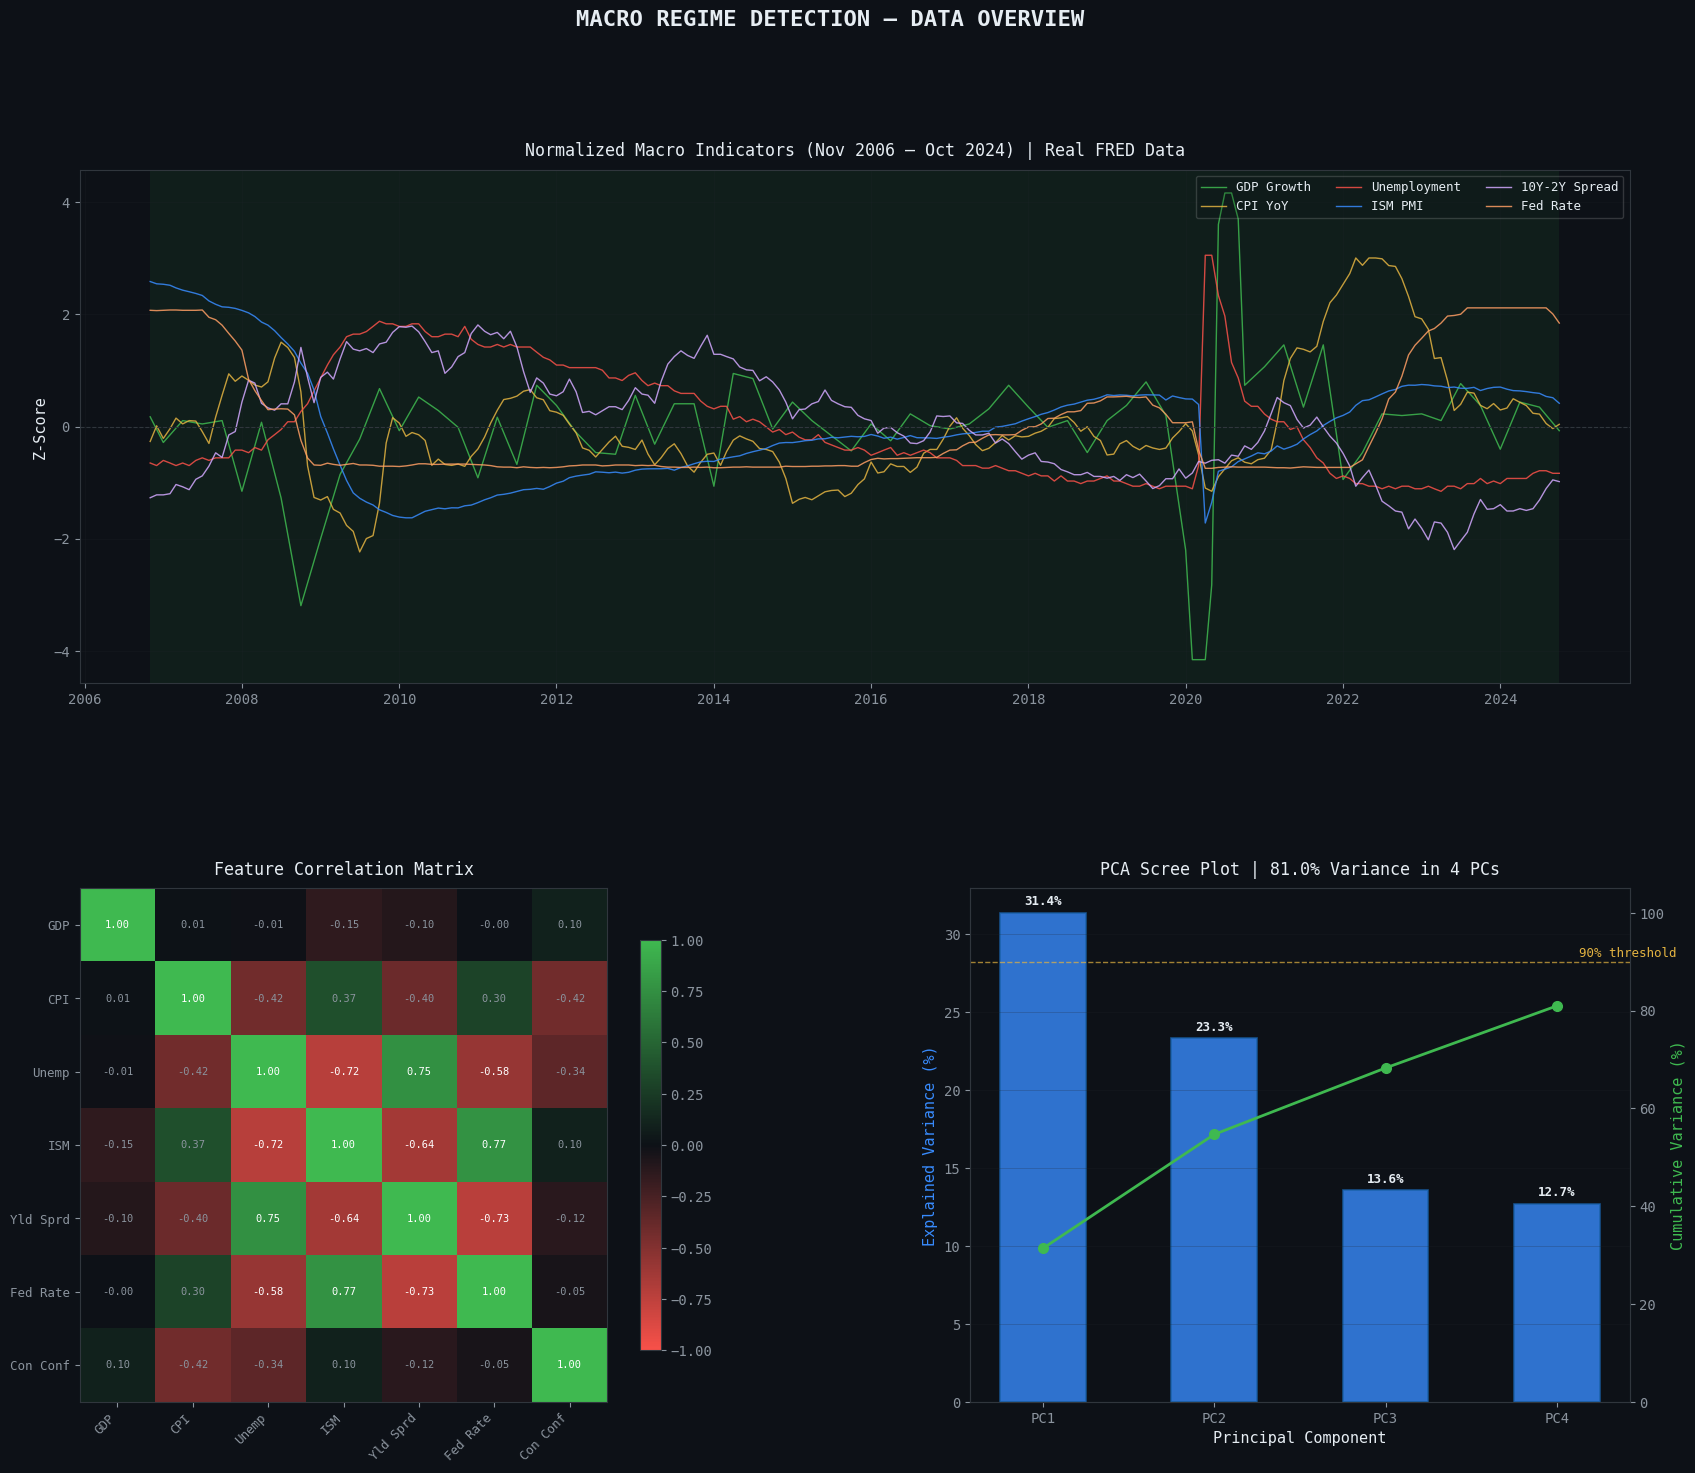

  ✓ Chart saved: data_overview.png


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# VISUALIZATION: PCA EXPLAINED VARIANCE & FEATURE CORRELATIONS
# ═══════════════════════════════════════════════════════════════════════════════

# Define regime_map here since we're using real FRED data (no synthetic generator)
regime_map = {0: 'Expansion', 1: 'Stagflation', 2: 'Recession', 3: 'Recovery'}

def plot_data_overview(macro_df: pd.DataFrame, fe: FeatureEngineer,
                       df_clean: pd.DataFrame) -> None:

    fig = plt.figure(figsize=(20, 16))
    fig.suptitle('MACRO REGIME DETECTION — DATA OVERVIEW',
                 fontsize=16, fontweight='bold', y=0.98, color='#e6edf3')

    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)
    ax1 = fig.add_subplot(gs[0, :])
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])

    # ── Panel A: Normalized Macro Series ─────────────────────────────────────
    # Dynamically use whatever features survived Cell 3 cleanup
    available_features = [f for f in MACRO_FEATURES if f in df_clean.columns]
    features_to_plot = available_features[:6]  # max 6 for readability

    scaler_viz = StandardScaler()
    X_norm = pd.DataFrame(
        scaler_viz.fit_transform(df_clean[features_to_plot]),
        index=df_clean.index,
        columns=features_to_plot
    )

    colors_series = ['#3fb950', '#e3b341', '#f85149', '#388bfd', '#d2a8ff', '#ff9e64']
    # Build labels map dynamically from whatever features we have
    labels_map = {
        'gdp_growth':    'GDP Growth',
        'cpi_yoy':       'CPI YoY',
        'unemployment':  'Unemployment',
        'ism_mfg':       'ISM PMI',
        'yield_spread':  '10Y-2Y Spread',
        'fed_rate':      'Fed Rate',
        'credit_spread': 'Credit Spread',
        'consumer_conf': 'Consumer Conf',
    }

    for col, color in zip(features_to_plot, colors_series):
        label = labels_map.get(col, col)
        ax1.plot(X_norm.index, X_norm[col], color=color, linewidth=1.0,
                 alpha=0.85, label=label)

    # Regime shading — with real data true_regime is all 0 (Expansion placeholder)
    # so shading will be a single color, which is fine
    regime_colors = {'Expansion': '#3fb950', 'Stagflation': '#e3b341',
                     'Recession': '#f85149', 'Recovery':    '#388bfd'}
    prev_regime, prev_date = None, None
    for date, reg in zip(df_clean.index, df_clean['true_regime'].values):
        reg_name = regime_map[reg]
        if reg_name != prev_regime:
            if prev_regime is not None:
                ax1.axvspan(prev_date, date, alpha=0.08,
                           color=regime_colors[prev_regime], linewidth=0)
            prev_regime, prev_date = reg_name, date
    if prev_regime:
        ax1.axvspan(prev_date, df_clean.index[-1], alpha=0.08,
                   color=regime_colors[prev_regime], linewidth=0)

    ax1.axhline(0, color='#30363d', linewidth=0.8, linestyle='--')
    ax1.legend(loc='upper right', ncol=3, framealpha=0.2, fontsize=9)
    ax1.set_title(
        f'Normalized Macro Indicators ({df_clean.index[0].strftime("%b %Y")} — '
        f'{df_clean.index[-1].strftime("%b %Y")}) | Real FRED Data',
        fontsize=12, pad=10)
    ax1.set_ylabel('Z-Score')
    ax1.grid(True, alpha=0.3)

    # ── Panel B: Correlation Heatmap ──────────────────────────────────────────
    # Use only features that actually exist in df_clean
    available_for_corr = [f for f in MACRO_FEATURES if f in df_clean.columns]
    corr = df_clean[available_for_corr].corr()

    cmap = LinearSegmentedColormap.from_list(
        'regime', ['#f85149', '#0d1117', '#3fb950'])
    im = ax2.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1, aspect='auto')

    ax2.set_xticks(range(len(available_for_corr)))
    ax2.set_yticks(range(len(available_for_corr)))

    # Build tick labels dynamically
    short_label_map = {
        'gdp_growth':    'GDP',
        'cpi_yoy':       'CPI',
        'unemployment':  'Unemp',
        'ism_mfg':       'ISM',
        'yield_spread':  'Yld Sprd',
        'fed_rate':      'Fed Rate',
        'credit_spread': 'Crdt Sprd',
        'consumer_conf': 'Con Conf',
    }
    short_labels = [short_label_map.get(f, f) for f in available_for_corr]
    ax2.set_xticklabels(short_labels, rotation=45, ha='right', fontsize=9)
    ax2.set_yticklabels(short_labels, fontsize=9)

    for i in range(len(available_for_corr)):
        for j in range(len(available_for_corr)):
            ax2.text(j, i, f"{corr.iloc[i,j]:.2f}",
                    ha='center', va='center', fontsize=7.5,
                    color='white' if abs(corr.iloc[i,j]) > 0.5 else '#8b949e')

    plt.colorbar(im, ax=ax2, shrink=0.8)
    ax2.set_title('Feature Correlation Matrix', fontsize=12, pad=10)

    # ── Panel C: PCA Scree Plot ───────────────────────────────────────────────
    ev = fe.pca.explained_variance_ratio_
    cum_ev = ev.cumsum()
    pc_labels = [f'PC{i+1}' for i in range(len(ev))]

    ax3_twin = ax3.twinx()
    bars = ax3.bar(pc_labels, ev * 100, color='#388bfd', alpha=0.8,
                   edgecolor='#185FA5', linewidth=1.2, width=0.5)
    ax3_twin.plot(pc_labels, cum_ev * 100, color='#3fb950', marker='o',
                  linewidth=2.0, markersize=7, label='Cumulative')
    ax3_twin.axhline(90, color='#e3b341', linewidth=1.0, linestyle='--', alpha=0.7)
    ax3_twin.text(len(pc_labels) - 0.3, 91, '90% threshold',
                  color='#e3b341', fontsize=9, ha='right')

    for bar, val in zip(bars, ev * 100):
        ax3.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                f'{val:.1f}%', ha='center', va='bottom', fontsize=9,
                color='#e6edf3', fontweight='bold')

    ax3.set_xlabel('Principal Component')
    ax3.set_ylabel('Explained Variance (%)', color='#388bfd')
    ax3_twin.set_ylabel('Cumulative Variance (%)', color='#3fb950')
    ax3_twin.set_ylim(0, 105)
    ax3.set_title(
        f'PCA Scree Plot | {cum_ev[-1]*100:.1f}% Variance in {len(ev)} PCs',
        fontsize=12, pad=10)
    ax3.grid(True, alpha=0.3, axis='y')

    plt.savefig('data_overview.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Chart saved: data_overview.png")


plot_data_overview(macro_df, fe, df_clean)

## 5. Hidden Markov Model: Fitting and Regime Detection

Fit a 4-state Gaussian HMM to the PCA-reduced macro features.

In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# HIDDEN MARKOV MODEL: FITTING & REGIME DETECTION
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Fit a 4-state Gaussian HMM to the PCA-reduced macro features.
# The HMM is the core model: it treats economic regimes as latent (hidden)
# states and the macro indicators as observable emissions from those states.
#
# THEORY:
#   - States: S ∈ {Expansion, Stagflation, Recession, Recovery} — unobserved
#   - Observations: O = PCA(macro features) — observed monthly
#   - Transition matrix A[i,j] = P(state j | state i) — learned by EM
#   - Emission params: μ_k, Σ_k per state — learned by EM (Gaussian HMM)
#   - Viterbi algorithm: finds most likely state sequence given observations
#   - Baum-Welch: EM algorithm to estimate all parameters from data
#
# INSTITUTIONAL ANALOGY:
#   This is conceptually identical to what Bridgewater's "All Weather"
#   framework does: identify which of 4 economic environments you're in
#   and size assets accordingly.

class MacroHMM:
    """
    Gaussian Hidden Markov Model for macro regime detection.

    Fits a GaussianHMM with multiple random restarts to avoid local optima,
    then maps discovered states to interpretable economic regimes using
    macro feature means (growth rates, inflation) as anchors.
    """

    def __init__(self, n_states: int = 4, n_iter: int = 500,
                 covariance_type: str = 'full', n_init: int = 10):
        self.n_states = n_states
        self.n_iter = n_iter
        self.covariance_type = covariance_type
        self.n_init = n_init
        self.best_model = None
        self.best_score = -np.inf
        self.state_mapping = {}      # HMM state index → regime name
        self.inv_mapping = {}        # regime name → HMM state index
        self.regime_labels = []      # Final regime label series

    def fit(self, X: np.ndarray, verbose: bool = True) -> 'MacroHMM':
        """
        Fit HMM with multiple random restarts (find global optimum).

        Uses Baum-Welch (EM algorithm) to estimate:
            - Initial state distribution (π)
            - Transition probability matrix (A)
            - Gaussian emission parameters (μ_k, Σ_k) per state

        Multiple restarts avoid local optima in the non-convex EM landscape.
        """
        if verbose:
            print(f"  Fitting GaussianHMM ({self.n_states} states, "
                  f"{self.covariance_type} covariance)...")
            print(f"  Running {self.n_init} random restarts to find global optimum...")

        scores = []
        for i in range(self.n_init):
            try:
                model = GaussianHMM(
                    n_components=self.n_states,
                    covariance_type=self.covariance_type,
                    n_iter=self.n_iter,
                    random_state=i * 7,     # Different seed each restart
                    verbose=False,
                )
                model.fit(X)
                score = model.score(X)
                scores.append(score)
                if score > self.best_score:
                    self.best_score = score
                    self.best_model = model
            except Exception as e:
                scores.append(-np.inf)

        if verbose:
            print(f"  Best log-likelihood:  {self.best_score:.2f}")
            print(f"  Score range:          [{min(scores):.2f}, {max(scores):.2f}]")
            converged = self.best_model.monitor_.converged
            print(f"  Converged:            {'✓ Yes' if converged else '✗ No'}")

        return self

    def label_states(self, X: np.ndarray, df_clean: pd.DataFrame,
                     verbose: bool = True) -> pd.Series:
        """
        Map anonymous HMM state indices to economic regime names.

        Mapping strategy:
            The HMM discovers 4 states but doesn't know their names.
            We anchor interpretation using two dimensions:
                1. GDP growth mean in each state  →  orders by growth level
                2. CPI inflation mean             →  distinguishes Stagflation from Recovery

        Logic:
            Sort states by mean GDP growth:
                Lowest  → Recession
                Highest → Recovery (fastest rebound) or Expansion (sustained)
            Then use CPI level to split Stagflation from the rest.
        """
        hidden_states = self.best_model.predict(X)
        gdp_col = df_clean.columns.get_loc('gdp_growth') if 'gdp_growth' in df_clean.columns else 0

        # Get mean GDP growth for each hidden state
        gdp_vals = df_clean['gdp_growth'].values[:len(hidden_states)]
        cpi_vals  = df_clean['cpi_yoy'].values[:len(hidden_states)]
        unemp_vals = df_clean['unemployment'].values[:len(hidden_states)]

        state_stats = {}
        for s in range(self.n_states):
            mask = hidden_states == s
            if mask.sum() > 0:
                state_stats[s] = {
                    'gdp':   gdp_vals[mask].mean(),
                    'cpi':   cpi_vals[mask].mean(),
                    'unemp': unemp_vals[mask].mean(),
                    'count': mask.sum(),
                }

        # Sort by GDP growth
        sorted_by_gdp = sorted(state_stats.keys(), key=lambda s: state_stats[s]['gdp'])
        # sorted_by_gdp[0] = lowest GDP → Recession
        # sorted_by_gdp[-1] = highest GDP → Recovery (fastest growth after trough)
        # Middle two: Expansion (sustained growth, mod inflation) vs Stagflation (high CPI)

        # Among middle two, higher CPI → Stagflation
        mid_states = sorted_by_gdp[1:-1]
        mid_sorted_cpi = sorted(mid_states, key=lambda s: state_stats[s]['cpi'])

        self.state_mapping = {
            sorted_by_gdp[0]:      'Recession',
            mid_sorted_cpi[0]:     'Expansion',
            mid_sorted_cpi[-1]:    'Stagflation',
            sorted_by_gdp[-1]:     'Recovery',
        }
        self.inv_mapping = {v: k for k, v in self.state_mapping.items()}

        self.regime_labels = pd.Series(
            [self.state_mapping[s] for s in hidden_states],
            index=df_clean.index
        )

        if verbose:
            print(f"\n  State Mapping (HMM State → Economic Regime):")
            for state, regime in sorted(self.state_mapping.items()):
                stats = state_stats[state]
                print(f"    State {state} → {regime:12s} | "
                      f"GDP={stats['gdp']:+.2f}%  CPI={stats['cpi']:.2f}%  "
                      f"Unemp={stats['unemp']:.1f}%  n={stats['count']}")

        return self.regime_labels

    def predict_proba(self, X: np.ndarray) -> pd.DataFrame:
        """
        Compute posterior probability of being in each regime at each time point.
        This is the key output used for smooth regime transition visualization
        and for weighting asset allocations probabilistically.
        """
        probs = self.best_model.predict_proba(X)
        regime_order = ['Expansion', 'Stagflation', 'Recession', 'Recovery']
        # Remap columns to regime names in standard order
        col_map = {self.inv_mapping[r]: r for r in regime_order if r in self.inv_mapping}
        prob_df = pd.DataFrame(probs, columns=range(self.n_states))
        prob_df = prob_df.rename(columns=self.state_mapping)
        return prob_df[regime_order]

    def get_transition_matrix(self) -> pd.DataFrame:
        """
        Extract and format the transition probability matrix.
        A[i,j] = probability of transitioning from regime i to regime j.
        High diagonal values indicate persistent regimes.
        """
        trans = self.best_model.transmat_
        regime_order = ['Expansion', 'Stagflation', 'Recession', 'Recovery']
        state_order = [self.inv_mapping.get(r, 0) for r in regime_order]
        trans_reordered = trans[np.ix_(state_order, state_order)]
        return pd.DataFrame(trans_reordered, index=regime_order, columns=regime_order)

    def get_aic_bic(self, X: np.ndarray) -> Dict[str, float]:
        """
        Compute AIC and BIC for model selection diagnostics.
        Lower is better. Use these to justify n_states=4 vs. alternatives.
        """
        log_likelihood = self.best_model.score(X) * len(X)
        # Parameters: transition (n^2-n), means (n*d), covariance (n*d^2 for full)
        d = X.shape[1]
        n_params = (self.n_states * (self.n_states - 1) +
                    self.n_states * d +
                    self.n_states * d * d)
        aic = 2 * n_params - 2 * log_likelihood
        bic = np.log(len(X)) * n_params - 2 * log_likelihood
        return {'log_likelihood': log_likelihood, 'AIC': aic, 'BIC': bic,
                'n_params': n_params}


# ── Fit the HMM ───────────────────────────────────────────────────────────────
print("=" * 60)
print("  HIDDEN MARKOV MODEL — FITTING")
print("=" * 60)

hmm_model = MacroHMM(
    n_states=N_STATES,
    n_iter=HMM_ITER,
    covariance_type=HMM_COVARIANCE,
    n_init=HMM_N_INIT,
)
hmm_model.fit(X_pca, verbose=True)
regime_labels = hmm_model.label_states(X_pca, df_clean, verbose=True)
regime_probs  = hmm_model.predict_proba(X_pca)
regime_probs.index = df_clean.index
transition_matrix = hmm_model.get_transition_matrix()
model_stats = hmm_model.get_aic_bic(X_pca)

# ── Model Selection Diagnostics ───────────────────────────────────────────────
print(f"\n  Model Information Criteria:")
print(f"    Log-Likelihood: {model_stats['log_likelihood']:,.2f}")
print(f"    AIC:            {model_stats['AIC']:,.2f}")
print(f"    BIC:            {model_stats['BIC']:,.2f}")
print(f"    # Parameters:   {model_stats['n_params']}")

# ── Transition Matrix ─────────────────────────────────────────────────────────
print(f"\n  Regime Transition Matrix (row=from, col=to):")
print(f"  {'':16s}" + ''.join(f"{'':>2s}{n[:8]:>10s}" for n in transition_matrix.columns))
print(f"  {'─'*65}")
for regime, row in transition_matrix.iterrows():
    vals_str = ''.join(f"{v:12.4f}" for v in row)
    print(f"  {regime:14s} |{vals_str}")

# ── Regime Duration Statistics ────────────────────────────────────────────────
print(f"\n  Detected Regime Statistics:")
detected_counts = regime_labels.value_counts()
for regime in REGIME_NAMES:
    count = detected_counts.get(regime, 0)
    pct = count / len(regime_labels) * 100
    # Estimate average persistence from diagonal of transition matrix
    if regime in transition_matrix.index:
        persistence = transition_matrix.loc[regime, regime]
        expected_duration = 1 / (1 - persistence) if persistence < 1 else np.inf
    else:
        expected_duration = 0
    print(f"    {regime:12s}: {count:3d} months ({pct:5.1f}%)  "
          f"Expected duration: {expected_duration:.1f} months")

print(f"\n  ✓ HMM fitting complete. Regime labels generated for {len(regime_labels)} months.")



  HIDDEN MARKOV MODEL — FITTING
  Fitting GaussianHMM (4 states, full covariance)...
  Running 10 random restarts to find global optimum...
  Best log-likelihood:  -861.30
  Score range:          [-933.13, -861.30]
  Converged:            ✓ Yes

  State Mapping (HMM State → Economic Regime):
    State 0 → Stagflation  | GDP=+1.25%  CPI=4.32%  Unemp=4.1%  n=62
    State 1 → Expansion    | GDP=+2.54%  CPI=1.51%  Unemp=4.5%  n=61
    State 2 → Recovery     | GDP=+2.97%  CPI=2.24%  Unemp=7.8%  n=76
    State 3 → Recession    | GDP=+0.32%  CPI=0.55%  Unemp=8.9%  n=17

  Model Information Criteria:
    Log-Likelihood: -186,041.17
    AIC:            372,266.35
    BIC:            372,576.87
    # Parameters:   92

  Regime Transition Matrix (row=from, col=to):
                      Expansio    Stagflat    Recessio    Recovery
  ─────────────────────────────────────────────────────────────────
  Expansion      |      0.9835      0.0165      0.0000      0.0000
  Stagflation    |      0.0000   

## 6. Qualitative Validation (Replaces Accuracy Check For Real Data)

In [7]:
# Cell 7 — Qualitative validation (replaces accuracy check for real data)
print("Most recent regime detected:")
print(f"  {regime_labels.index[-1].strftime('%B %Y')}: {regime_labels.iloc[-1]}")
print(f"  Confidence: {regime_probs.iloc[-1].max():.1%}")
print("\nRegime probability breakdown:")
for regime, prob in regime_probs.iloc[-1].sort_values(ascending=False).items():
    bar = '█' * int(prob * 30)
    print(f"  {regime:12s}: {prob:5.1%}  {bar}")

Most recent regime detected:
  October 2024: Stagflation
  Confidence: 100.0%

Regime probability breakdown:
  Stagflation : 100.0%  █████████████████████████████
  Recession   :  0.0%  
  Recovery    :  0.0%  
  Expansion   :  0.0%  


## 7. Core Visualization: Regime Detection Timeline

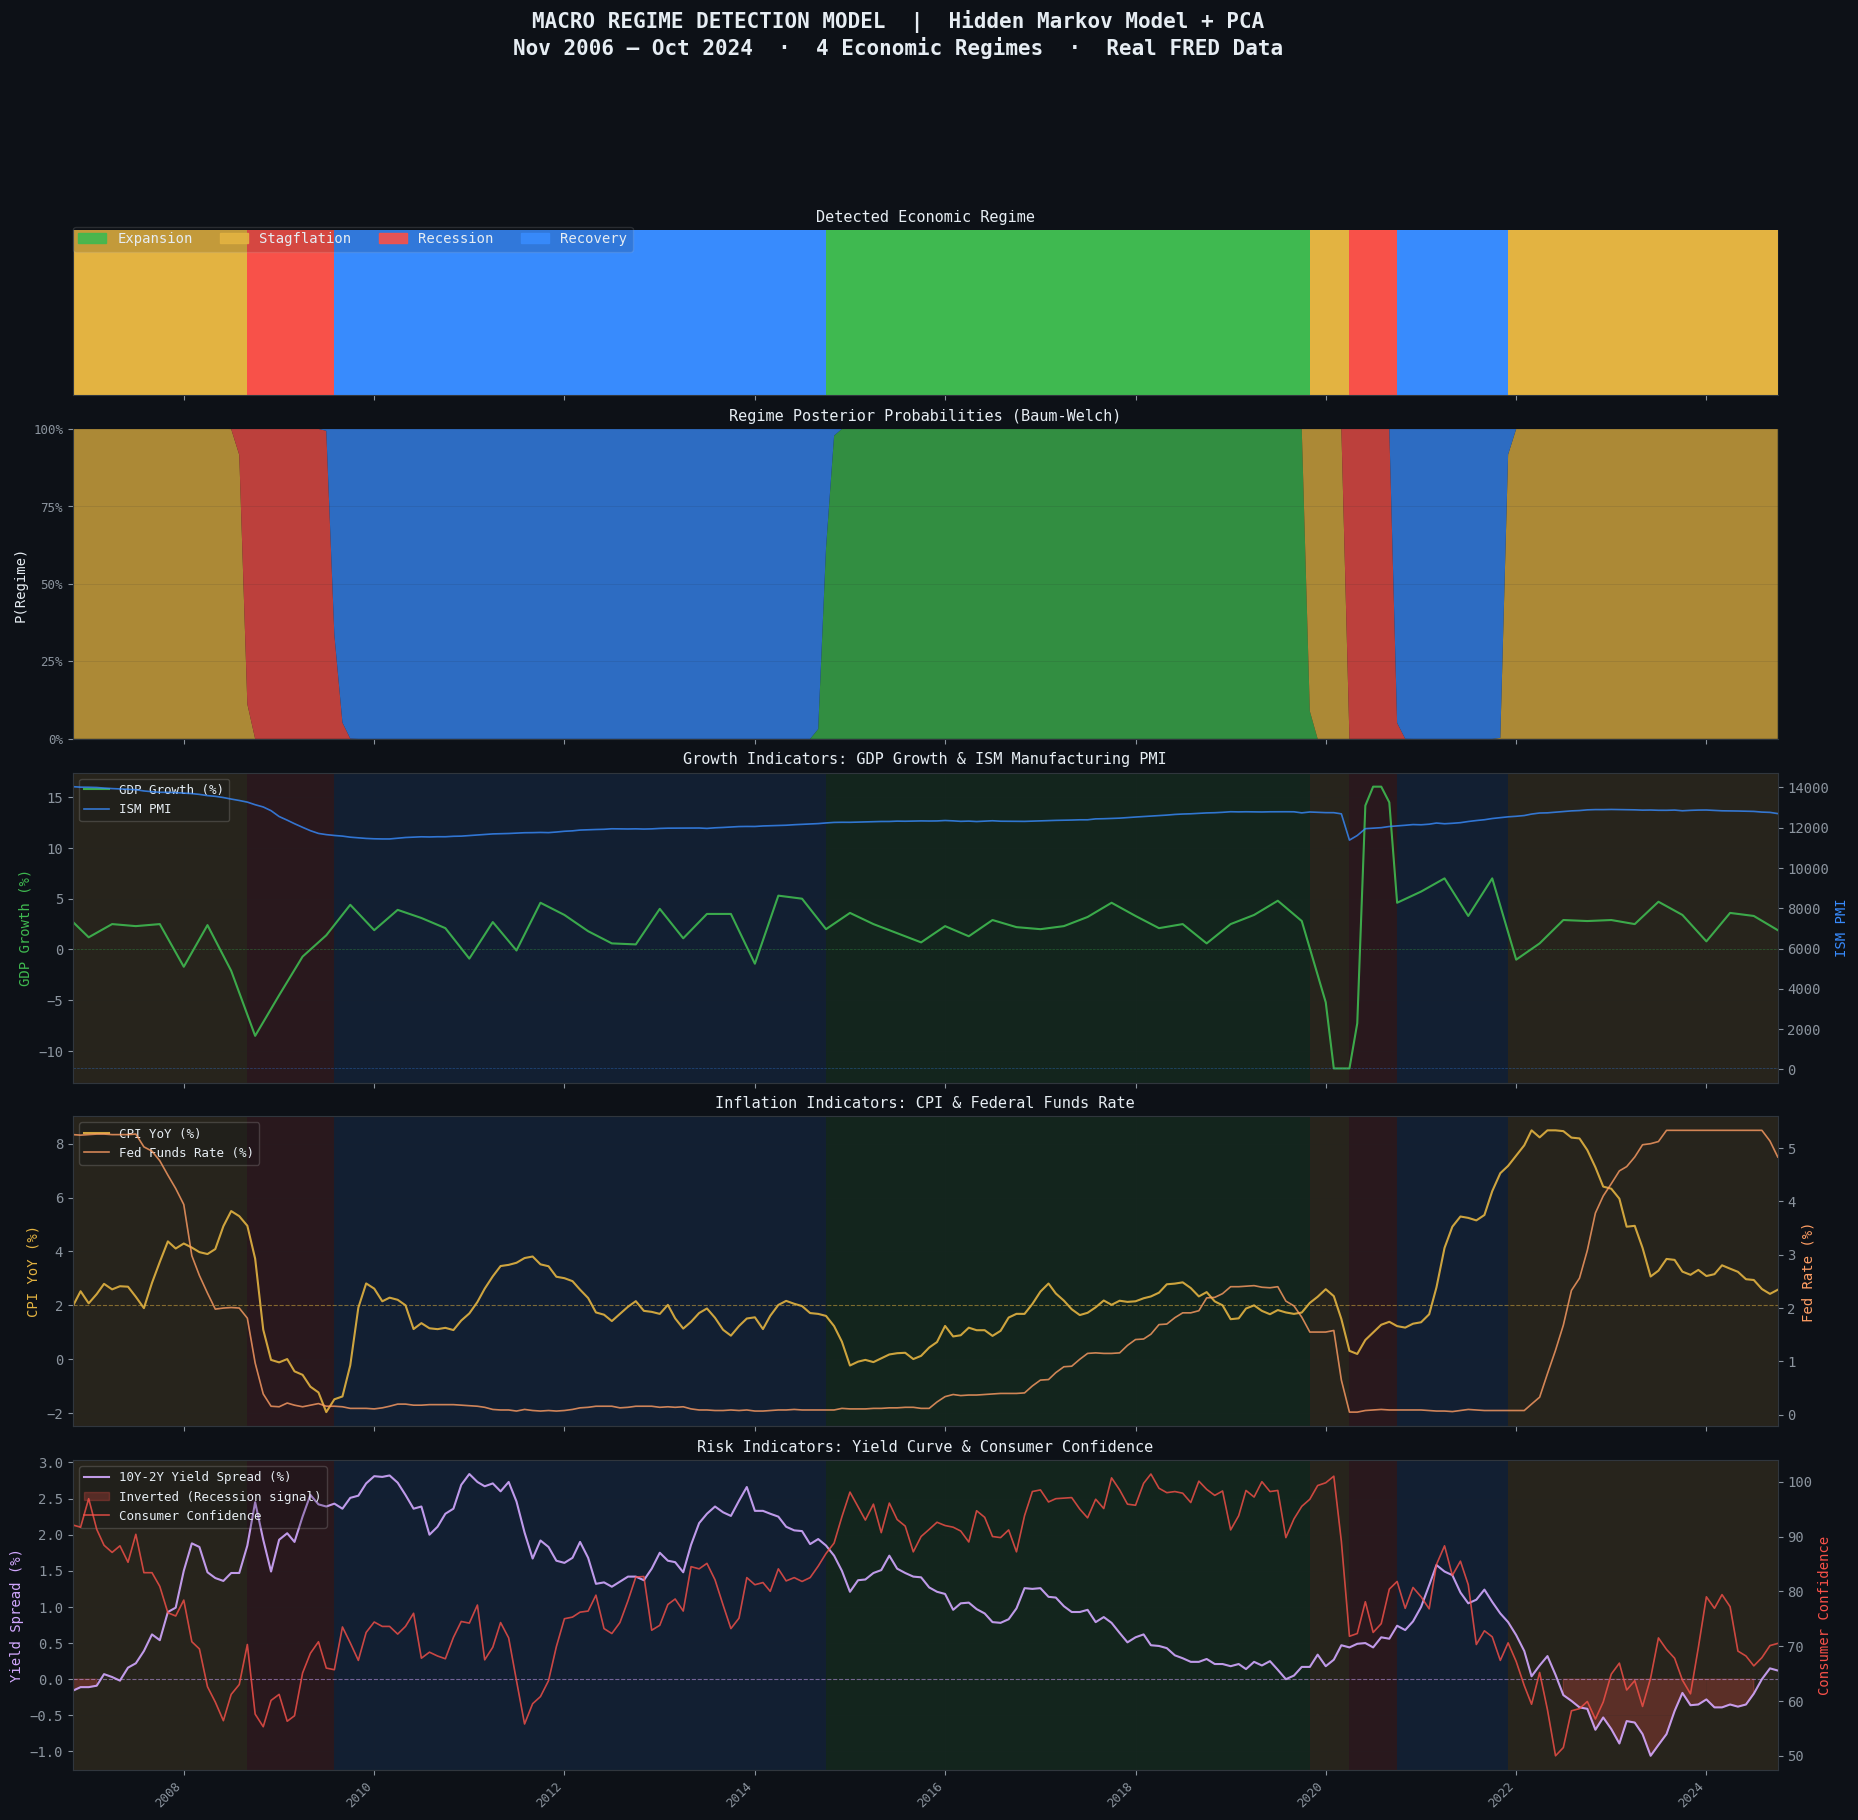

  ✓ Flagship chart saved: regime_timeline.png


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# CORE VISUALIZATION: REGIME DETECTION TIMELINE
# ═══════════════════════════════════════════════════════════════════════════════

def plot_regime_timeline(regime_labels: pd.Series, regime_probs: pd.DataFrame,
                          df_clean: pd.DataFrame) -> None:

    fig = plt.figure(figsize=(22, 20))
    start_yr = df_clean.index[0].strftime('%b %Y')
    end_yr   = df_clean.index[-1].strftime('%b %Y')
    fig.suptitle(
        f'MACRO REGIME DETECTION MODEL  |  Hidden Markov Model + PCA\n'
        f'{start_yr} — {end_yr}  ·  4 Economic Regimes  ·  Real FRED Data',
        fontsize=15, fontweight='bold', y=0.99, color='#e6edf3'
    )

    gs = gridspec.GridSpec(5, 1, figure=fig, hspace=0.12,
                           height_ratios=[0.8, 1.5, 1.5, 1.5, 1.5])
    axes = [fig.add_subplot(gs[i]) for i in range(5)]

    def shade_regimes(ax, regime_labels, alpha=0.25):
        prev_regime, prev_date = None, None
        for date, reg in regime_labels.items():
            if reg != prev_regime:
                if prev_regime is not None:
                    ax.axvspan(prev_date, date, alpha=alpha,
                              color=PALETTE[prev_regime], linewidth=0)
                prev_regime, prev_date = reg, date
        if prev_regime:
            ax.axvspan(prev_date, regime_labels.index[-1], alpha=alpha,
                      color=PALETTE[prev_regime], linewidth=0)

    # ── Panel 1: Regime Color Bar ─────────────────────────────────────────────
    ax = axes[0]
    prev_regime, prev_date = None, None
    for date, reg in regime_labels.items():
        if reg != prev_regime:
            if prev_regime is not None:
                ax.axvspan(prev_date, date, alpha=1.0,
                          color=PALETTE[prev_regime], linewidth=0)
            prev_regime, prev_date = reg, date
    if prev_regime:
        ax.axvspan(prev_date, regime_labels.index[-1], alpha=1.0,
                  color=PALETTE[prev_regime], linewidth=0)

    ax.set_yticks([])
    ax.set_xlim(df_clean.index[0], df_clean.index[-1])
    ax.set_title('Detected Economic Regime', pad=6, fontsize=11)
    ax.tick_params(labelbottom=False)
    ax.set_facecolor('#0d1117')
    patches = [mpatches.Patch(color=c, label=n, alpha=0.9)
               for n, c in PALETTE.items()]
    ax.legend(handles=patches, loc='upper left', ncol=4,
              framealpha=0.15, fontsize=10,
              bbox_to_anchor=(0, 1.02), borderaxespad=0)

    # ── Panel 2: Regime Posterior Probabilities ───────────────────────────────
    ax = axes[1]
    prob_colors = [PALETTE[r] for r in regime_probs.columns]
    ax.stackplot(regime_probs.index,
                 [regime_probs[col].values for col in regime_probs.columns],
                 labels=list(regime_probs.columns),
                 colors=prob_colors, alpha=0.75)
    ax.set_ylabel('P(Regime)', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['0%', '25%', '50%', '75%', '100%'], fontsize=9)
    ax.set_title('Regime Posterior Probabilities (Baum-Welch)', pad=6, fontsize=11)
    ax.tick_params(labelbottom=False)
    ax.grid(True, alpha=0.15, axis='y')

    # ── Panel 3: GDP Growth & ISM PMI ─────────────────────────────────────────
    ax = axes[2]
    shade_regimes(ax, regime_labels, alpha=0.12)
    ax2_twin = ax.twinx()
    ax.plot(df_clean.index, df_clean['gdp_growth'], color='#3fb950',
            linewidth=1.5, label='GDP Growth (%)', alpha=0.9)
    ax.axhline(0, color='#3fb950', linewidth=0.5, linestyle='--', alpha=0.4)
    ax2_twin.plot(df_clean.index, df_clean['ism_mfg'], color='#388bfd',
                  linewidth=1.2, label='ISM PMI', alpha=0.8)
    ax2_twin.axhline(50, color='#388bfd', linewidth=0.5, linestyle='--', alpha=0.4)
    ax.set_ylabel('GDP Growth (%)', color='#3fb950', fontsize=10)
    ax2_twin.set_ylabel('ISM PMI', color='#388bfd', fontsize=10)
    ax.set_title('Growth Indicators: GDP Growth & ISM Manufacturing PMI',
                 pad=6, fontsize=11)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2_twin.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left',
              framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.15)
    ax.tick_params(labelbottom=False)

    # ── Panel 4: CPI & Fed Funds Rate ─────────────────────────────────────────
    ax = axes[3]
    shade_regimes(ax, regime_labels, alpha=0.12)
    ax4_twin = ax.twinx()
    ax.plot(df_clean.index, df_clean['cpi_yoy'], color='#e3b341',
            linewidth=1.5, label='CPI YoY (%)', alpha=0.9)
    ax.axhline(2.0, color='#e3b341', linewidth=0.8, linestyle='--', alpha=0.5)
    ax4_twin.plot(df_clean.index, df_clean['fed_rate'], color='#ff9e64',
                  linewidth=1.2, label='Fed Funds Rate (%)', alpha=0.8)
    ax.set_ylabel('CPI YoY (%)', color='#e3b341', fontsize=10)
    ax4_twin.set_ylabel('Fed Rate (%)', color='#ff9e64', fontsize=10)
    ax.set_title('Inflation Indicators: CPI & Federal Funds Rate',
                 pad=6, fontsize=11)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax4_twin.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left',
              framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.15)
    ax.tick_params(labelbottom=False)

    # ── Panel 5: Yield Spread & Consumer Confidence ───────────────────────────
    # Note: credit_spread was dropped due to insufficient FRED history.
    # Consumer confidence is used instead as the second risk indicator.
    ax = axes[4]
    shade_regimes(ax, regime_labels, alpha=0.12)
    ax5_twin = ax.twinx()

    ax.plot(df_clean.index, df_clean['yield_spread'], color='#d2a8ff',
            linewidth=1.5, label='10Y-2Y Yield Spread (%)', alpha=0.9)
    ax.axhline(0, color='#d2a8ff', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.fill_between(df_clean.index, df_clean['yield_spread'], 0,
                   where=df_clean['yield_spread'] < 0,
                   color='#f85149', alpha=0.25, label='Inverted (Recession signal)')

    # Use consumer_conf as second indicator since credit_spread was dropped
    if 'consumer_conf' in df_clean.columns:
        ax5_twin.plot(df_clean.index, df_clean['consumer_conf'], color='#f85149',
                      linewidth=1.2, label='Consumer Confidence', alpha=0.8)
        ax5_twin.set_ylabel('Consumer Confidence', color='#f85149', fontsize=10)
        ax.set_title('Risk Indicators: Yield Curve & Consumer Confidence',
                     pad=6, fontsize=11)
    else:
        ax5_twin.set_ylabel('', fontsize=10)
        ax.set_title('Risk Indicators: Yield Curve', pad=6, fontsize=11)

    ax.set_ylabel('Yield Spread (%)', color='#d2a8ff', fontsize=10)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax5_twin.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left',
              framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.15)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)

    for ax_i in axes:
        ax_i.spines['top'].set_visible(False)
        ax_i.spines['right'].set_alpha(0.3)
        ax_i.set_facecolor('#0d1117')
        ax_i.set_xlim(df_clean.index[0], df_clean.index[-1])

    plt.savefig('regime_timeline.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Flagship chart saved: regime_timeline.png")


plot_regime_timeline(regime_labels, regime_probs, df_clean)

## 8. HMM Structure Visualization

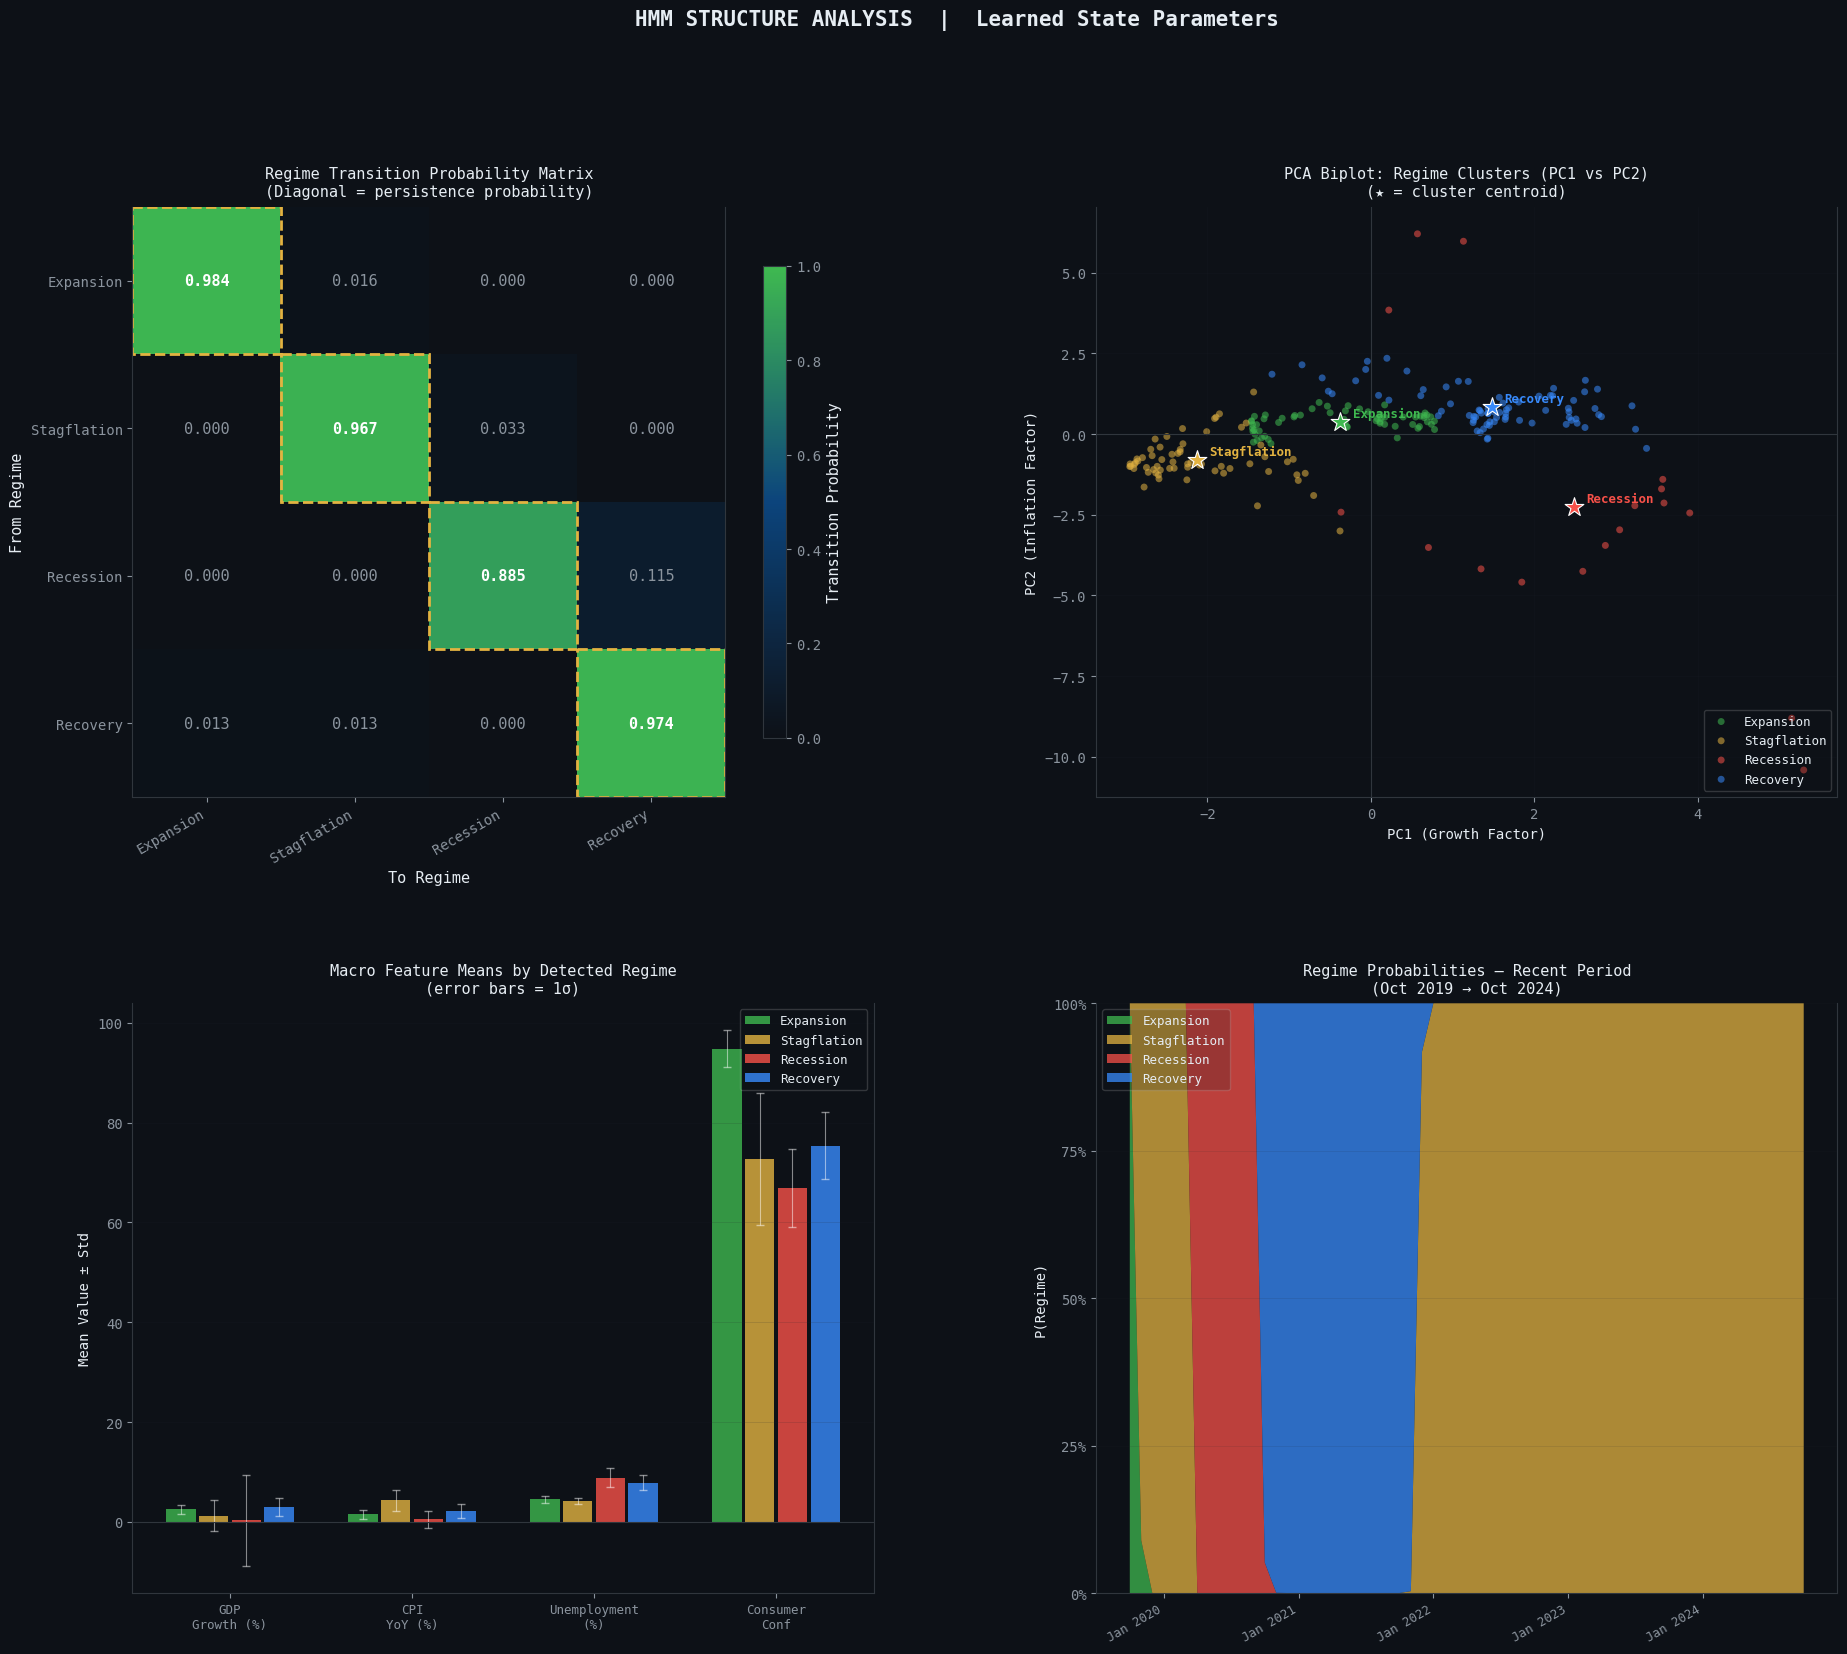

  ✓ Chart saved: hmm_structure.png


In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# HMM STRUCTURE VISUALIZATION
# ═══════════════════════════════════════════════════════════════════════════════

def plot_hmm_structure(transition_matrix: pd.DataFrame, regime_probs: pd.DataFrame,
                        X_pca: np.ndarray, regime_labels: pd.Series,
                        df_clean: pd.DataFrame) -> None:

    fig = plt.figure(figsize=(22, 18))
    fig.suptitle('HMM STRUCTURE ANALYSIS  |  Learned State Parameters',
                 fontsize=15, fontweight='bold', y=0.99, color='#e6edf3')

    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, 0])
    ax4 = fig.add_subplot(gs[1, 1])

    # ── Panel A: Transition Matrix Heatmap ────────────────────────────────────
    trans_arr = transition_matrix.values
    cmap_trans = LinearSegmentedColormap.from_list(
        'trans', ['#0d1117', '#0C447C', '#3fb950'])
    im = ax1.imshow(trans_arr, cmap=cmap_trans, vmin=0, vmax=1, aspect='auto')
    plt.colorbar(im, ax=ax1, shrink=0.8, label='Transition Probability')

    for i in range(len(REGIME_NAMES)):
        for j in range(len(REGIME_NAMES)):
            val = trans_arr[i, j]
            ax1.text(j, i, f"{val:.3f}", ha='center', va='center',
                    fontsize=11, color='white' if val > 0.4 else '#8b949e',
                    fontweight='bold' if i == j else 'normal')

    ax1.set_xticks(range(len(REGIME_NAMES)))
    ax1.set_yticks(range(len(REGIME_NAMES)))
    ax1.set_xticklabels(REGIME_NAMES, rotation=30, ha='right', fontsize=10)
    ax1.set_yticklabels(REGIME_NAMES, fontsize=10)
    ax1.set_xlabel('To Regime')
    ax1.set_ylabel('From Regime')
    ax1.set_title('Regime Transition Probability Matrix\n(Diagonal = persistence probability)',
                  fontsize=11, pad=8)
    for i in range(len(REGIME_NAMES)):
        ax1.add_patch(plt.Rectangle((i-0.5, i-0.5), 1, 1,
                                    fill=False, edgecolor='#e3b341',
                                    linewidth=2.0, linestyle='--'))

    # ── Panel B: PCA Biplot (PC1 vs PC2) ─────────────────────────────────────
    for regime in REGIME_NAMES:
        mask = regime_labels == regime
        if mask.sum() > 0:
            idx = mask.values
            ax2.scatter(X_pca[idx, 0], X_pca[idx, 1],
                       c=PALETTE[regime], label=regime, alpha=0.55,
                       s=25, edgecolors='none')

    for regime in REGIME_NAMES:
        mask = (regime_labels == regime).values
        if mask.sum() > 0:
            cx, cy = X_pca[mask, 0].mean(), X_pca[mask, 1].mean()
            ax2.scatter([cx], [cy], c=PALETTE[regime], s=200, marker='*',
                       edgecolors='white', linewidths=0.8, zorder=5)
            ax2.annotate(regime, (cx, cy), xytext=(cx+0.15, cy+0.15),
                        fontsize=9, color=PALETTE[regime], fontweight='bold')

    ax2.set_xlabel('PC1 (Growth Factor)', fontsize=10)
    ax2.set_ylabel('PC2 (Inflation Factor)', fontsize=10)
    ax2.set_title('PCA Biplot: Regime Clusters (PC1 vs PC2)\n(★ = cluster centroid)',
                  fontsize=11, pad=8)
    ax2.legend(loc='lower right', framealpha=0.2, fontsize=9)
    ax2.grid(True, alpha=0.2)
    ax2.axhline(0, color='#30363d', linewidth=0.8)
    ax2.axvline(0, color='#30363d', linewidth=0.8)

    # ── Panel C: Feature Distributions per Regime ─────────────────────────────
    # Dynamically pick 4 available features — never hardcode credit_spread
    preferred = ['gdp_growth', 'cpi_yoy', 'unemployment', 'consumer_conf']
    features_to_show = [f for f in preferred if f in df_clean.columns]

    # Fallback: if any preferred feature is missing, fill from MACRO_FEATURES
    if len(features_to_show) < 4:
        extras = [f for f in MACRO_FEATURES
                  if f in df_clean.columns and f not in features_to_show]
        features_to_show += extras[:4 - len(features_to_show)]

    plot_df = df_clean[features_to_show].copy()
    plot_df['Regime'] = regime_labels.values

    # Build x-axis labels dynamically
    label_map = {
        'gdp_growth':    'GDP\nGrowth (%)',
        'cpi_yoy':       'CPI\nYoY (%)',
        'unemployment':  'Unemployment\n(%)',
        'consumer_conf': 'Consumer\nConf',
        'ism_mfg':       'ISM\nPMI',
        'yield_spread':  'Yield\nSpread (%)',
        'fed_rate':      'Fed\nRate (%)',
        'credit_spread': 'Credit\nSpread (%)',
    }
    x_labels = [label_map.get(f, f) for f in features_to_show]

    positions = np.arange(len(features_to_show))
    width = 0.18
    offset_map = {'Expansion': -1.5, 'Stagflation': -0.5,
                  'Recession': 0.5,  'Recovery':    1.5}

    for regime, offset in offset_map.items():
        subset = plot_df[plot_df['Regime'] == regime][features_to_show]
        if len(subset) == 0:
            continue
        feat_means = subset.mean()
        feat_stds  = subset.std()
        ax3.bar(positions + offset * width, feat_means.values,
               width * 0.9, yerr=feat_stds.values, capsize=3,
               color=PALETTE[regime], alpha=0.8, label=regime,
               error_kw={'ecolor': 'white', 'alpha': 0.5, 'linewidth': 0.8})

    ax3.set_xticks(positions)
    ax3.set_xticklabels(x_labels, fontsize=9)
    ax3.set_ylabel('Mean Value ± Std', fontsize=10)
    ax3.set_title('Macro Feature Means by Detected Regime\n(error bars = 1σ)',
                  fontsize=11, pad=8)
    ax3.legend(loc='upper right', framealpha=0.2, fontsize=9)
    ax3.grid(True, alpha=0.2, axis='y')
    ax3.axhline(0, color='#30363d', linewidth=0.8)

    # ── Panel D: Recent Regime Probability ────────────────────────────────────
    recent_probs = regime_probs.loc[
        regime_probs.index >= (regime_probs.index[-1] - pd.DateOffset(months=60))]
    prob_colors = [PALETTE[r] for r in recent_probs.columns]
    ax4.stackplot(recent_probs.index,
                  [recent_probs[col].values for col in recent_probs.columns],
                  colors=prob_colors, alpha=0.75,
                  labels=list(recent_probs.columns))

    ax4.set_ylabel('P(Regime)', fontsize=10)
    ax4.set_ylim(0, 1)
    ax4.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax4.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])
    ax4.set_title(
        f'Regime Probabilities — Recent Period\n'
        f'({recent_probs.index[0].strftime("%b %Y")} → '
        f'{recent_probs.index[-1].strftime("%b %Y")})',
        fontsize=11, pad=8)
    ax4.legend(loc='upper left', framealpha=0.2, fontsize=9)
    ax4.grid(True, alpha=0.15, axis='y')
    ax4.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax4.get_xticklabels(), rotation=30, ha='right', fontsize=9)

    for ax in [ax1, ax2, ax3, ax4]:
        ax.set_facecolor('#0d1117')
        ax.spines['top'].set_visible(False)

    plt.savefig('hmm_structure.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Chart saved: hmm_structure.png")


plot_hmm_structure(transition_matrix, regime_probs, X_pca, regime_labels, df_clean)

## 9. Portfolio Backtesting Engine

Backtest regime-aware asset allocation against the 60/40 benchmark.

In [10]:
# ═══════════════════════════════════════════════════════════════════════════════
# PORTFOLIO BACKTESTING ENGINE
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Backtest regime-aware asset allocation against the 60/40 benchmark.
# This is the "so what" of the model — does regime detection actually improve returns?
#
# METHODOLOGY:
#   At each month-end, we observe the regime probabilities and set weights.
#   Two approaches are tested:
#     Hard allocation: use the dominant regime's fixed weights
#     Soft allocation: probability-weighted blend of all regime weights
#
# INSTITUTIONAL FRAMEWORK:
#   This mirrors Bridgewater's All Weather thinking: different assets
#   perform best in different environments. Knowing the environment
#   ahead of time (even imperfectly) adds value over static allocation.

class PortfolioBacktester:
    """
    Regime-aware portfolio backtesting engine.

    Implements:
        1. Hard regime allocation (use dominant regime weights)
        2. Soft/probabilistic allocation (blend weights by regime probability)
        3. 60/40 benchmark
        4. Equal weight baseline
        5. Each-asset benchmark

    Computes a full suite of institutional performance metrics.
    """

    def __init__(self, asset_returns: pd.DataFrame, regime_labels: pd.Series,
                 regime_probs: pd.DataFrame, transaction_cost_bps: float = 10.0):
        """
        Args:
            asset_returns:      Monthly returns (%) for each asset
            regime_labels:      Detected regime for each month
            regime_probs:       Posterior probabilities for each regime
            transaction_cost_bps: Round-trip transaction cost in basis points
        """
        self.asset_returns  = asset_returns
        self.regime_labels  = regime_labels
        self.regime_probs   = regime_probs
        self.tc_bps         = transaction_cost_bps / 10000.0  # Convert to decimal
        self.results        = {}

    def _compute_weights_hard(self) -> pd.DataFrame:
        """
        Hard regime allocation: at each month, apply the fixed weights
        corresponding to the detected regime.
        """
        weight_cols = ['w_equity', 'w_bond', 'w_gold', 'w_cmdty']
        weights = pd.DataFrame(index=self.regime_labels.index, columns=weight_cols)

        for date, regime in self.regime_labels.items():
            w = REGIME_WEIGHTS[regime]
            weights.loc[date] = w

        return weights.astype(float)

    def _compute_weights_soft(self) -> pd.DataFrame:
        """
        Soft (probabilistic) allocation: blend regime weights by probability.
        This avoids sharp switches between regimes and is more realistic
        for a fund that can't instantaneously rebalance.

        w_soft = Σ_r P(regime=r) × w_hard(r)
        """
        regime_order  = ['Expansion', 'Stagflation', 'Recession', 'Recovery']
        weight_matrix = np.array([REGIME_WEIGHTS[r] for r in regime_order])  # 4×4

        probs_aligned = self.regime_probs.loc[self.regime_labels.index, regime_order]
        soft_weights  = probs_aligned.values @ weight_matrix  # n×4

        return pd.DataFrame(soft_weights, index=self.regime_labels.index,
                           columns=['w_equity', 'w_bond', 'w_gold', 'w_cmdty'])

    def _apply_transaction_costs(self, weights: pd.DataFrame) -> pd.Series:
        """
        Compute turnover-based transaction costs.
        TC = Σ |w_t - w_{t-1}| × cost_per_unit
        """
        turnover = weights.diff().abs().sum(axis=1)
        costs = turnover * self.tc_bps
        return costs

    def _compute_portfolio_returns(self, weights: pd.DataFrame,
                                    strategy_name: str) -> pd.Series:
        """
        Compute net-of-cost monthly portfolio returns.
        """
        # Align asset returns with weights
        asset_cols = ['equity_ret', 'bond_ret', 'gold_ret', 'cmdty_ret']
        ret = self.asset_returns[asset_cols].loc[weights.index]
        tc  = self._apply_transaction_costs(weights)

        gross_returns = (weights.values * ret.values).sum(axis=1)
        net_returns   = gross_returns - tc.values

        return pd.Series(net_returns, index=weights.index, name=strategy_name)

    def backtest_all(self) -> Dict[str, pd.Series]:
        """
        Run all strategies and return dict of monthly return series.
        """
        # 1. Regime-Aware Hard Allocation
        w_hard   = self._compute_weights_hard()
        ret_hard = self._compute_portfolio_returns(w_hard, 'Regime-Aware (Hard)')

        # 2. Regime-Aware Soft/Probabilistic Allocation
        w_soft   = self._compute_weights_soft()
        ret_soft = self._compute_portfolio_returns(w_soft, 'Regime-Aware (Soft)')

        # 3. 60/40 Benchmark (static, no regime)
        w_bench  = pd.DataFrame(
            np.tile(BENCHMARK_WEIGHTS, (len(w_hard), 1)),
            index=w_hard.index,
            columns=['w_equity', 'w_bond', 'w_gold', 'w_cmdty']
        )
        ret_bench = self._compute_portfolio_returns(w_bench, '60/40 Benchmark')

        # 4. Equal Weight Baseline (25% each)
        w_equal  = pd.DataFrame(
            np.tile([0.25, 0.25, 0.25, 0.25], (len(w_hard), 1)),
            index=w_hard.index,
            columns=['w_equity', 'w_bond', 'w_gold', 'w_cmdty']
        )
        ret_equal = self._compute_portfolio_returns(w_equal, 'Equal Weight')

        self.results = {
            'Regime-Aware (Hard)': ret_hard / 100,
            'Regime-Aware (Soft)': ret_soft / 100,
            '60/40 Benchmark':     ret_bench / 100,
            'Equal Weight':        ret_equal / 100,
        }
        self.weights_hard = w_hard
        self.weights_soft = w_soft

        print(f"  Backtested {len(ret_hard)} months "
              f"({ret_hard.index[0].strftime('%b %Y')} → {ret_hard.index[-1].strftime('%b %Y')})")

        return self.results

    @staticmethod
    def _compute_metrics(returns: pd.Series, rf_monthly: float = 0.004) -> Dict:
        """
        Compute a full suite of institutional performance metrics.

        Args:
            returns:    Monthly return series (decimal, not %)
            rf_monthly: Monthly risk-free rate (default ≈ 4.8% annualized)
        """
        cum_ret     = (1 + returns).cumprod()
        total_ret   = cum_ret.iloc[-1] - 1
        n_months    = len(returns)
        n_years     = n_months / 12

        ann_ret     = (1 + total_ret) ** (1 / n_years) - 1
        ann_vol     = returns.std() * np.sqrt(12)
        sharpe      = (ann_ret - rf_monthly * 12) / ann_vol if ann_vol > 0 else 0

        # Sortino (downside deviation only)
        downside    = returns[returns < 0]
        dd_vol      = downside.std() * np.sqrt(12) if len(downside) > 0 else 1e-9
        sortino     = (ann_ret - rf_monthly * 12) / dd_vol

        # Maximum Drawdown
        peak        = cum_ret.cummax()
        drawdown    = (cum_ret - peak) / peak
        max_dd      = drawdown.min()

        # Calmar Ratio (return per unit of max drawdown)
        calmar      = ann_ret / abs(max_dd) if max_dd != 0 else 0

        # Hit Rate (% months positive)
        hit_rate    = (returns > 0).mean()

        # Worst Month / Best Month
        worst_month = returns.min()
        best_month  = returns.max()

        # Value at Risk (95%, Historical)
        var_95      = np.percentile(returns, 5)

        return {
            'Total Return':     total_ret,
            'Ann. Return':      ann_ret,
            'Ann. Volatility':  ann_vol,
            'Sharpe Ratio':     sharpe,
            'Sortino Ratio':    sortino,
            'Max Drawdown':     max_dd,
            'Calmar Ratio':     calmar,
            'Hit Rate':         hit_rate,
            'Best Month':       best_month,
            'Worst Month':      worst_month,
            'VaR 95%':          var_95,
            'Cum Returns':      cum_ret,
        }

    def generate_report(self) -> pd.DataFrame:
        """
        Generate performance comparison table across all strategies.
        """
        metric_rows = {}
        for name, rets in self.results.items():
            metric_rows[name] = self._compute_metrics(rets)

        display_metrics = ['Ann. Return', 'Ann. Volatility', 'Sharpe Ratio',
                           'Sortino Ratio', 'Max Drawdown', 'Calmar Ratio',
                           'Hit Rate', 'Total Return', 'Worst Month', 'VaR 95%']

        report_data = {}
        for metric in display_metrics:
            report_data[metric] = {name: metric_rows[name][metric]
                                   for name in self.results.keys()}

        self._metric_data = metric_rows
        return pd.DataFrame(report_data).T


# ── Run Backtest ──────────────────────────────────────────────────────────────
print("=" * 60)
print("  PORTFOLIO BACKTEST ENGINE")
print("=" * 60)

backtester = PortfolioBacktester(
    asset_returns=asset_clean,
    regime_labels=regime_labels,
    regime_probs=regime_probs,
    transaction_cost_bps=10.0
)

backtest_results = backtester.backtest_all()
performance_report = backtester.generate_report()

print(f"\n  PERFORMANCE COMPARISON (Net of 10 bps transaction costs)")
print(f"  {'─'*80}")
fmt_map = {
    'Ann. Return': '{:.2%}', 'Ann. Volatility': '{:.2%}',
    'Sharpe Ratio': '{:.3f}', 'Sortino Ratio': '{:.3f}',
    'Max Drawdown': '{:.2%}', 'Calmar Ratio': '{:.3f}',
    'Hit Rate': '{:.1%}', 'Total Return': '{:.1%}',
    'Worst Month': '{:.2%}', 'VaR 95%': '{:.2%}',
}

header = f"  {'Metric':22s}"
for name in backtest_results.keys():
    header += f"  {name[:18]:>18s}"
print(header)
print(f"  {'─'*80}")

for metric, fmt in fmt_map.items():
    row = f"  {metric:22s}"
    for name in backtest_results.keys():
        val = performance_report.loc[metric, name]
        row += f"  {fmt.format(val):>18s}"
    print(row)

# Compute outperformance vs. benchmark
hard_sharpe  = performance_report.loc['Sharpe Ratio', 'Regime-Aware (Hard)']
bench_sharpe = performance_report.loc['Sharpe Ratio', '60/40 Benchmark']
hard_ret     = performance_report.loc['Ann. Return', 'Regime-Aware (Hard)']
bench_ret    = performance_report.loc['Ann. Return', '60/40 Benchmark']

print(f"\n  Regime-Aware vs. 60/40 Benchmark:")
print(f"    Alpha (Ann. Return):  {(hard_ret - bench_ret)*100:+.2f}%")
print(f"    Sharpe Improvement:   {hard_sharpe - bench_sharpe:+.3f}")


  PORTFOLIO BACKTEST ENGINE
  Backtested 216 months (Nov 2006 → Oct 2024)

  PERFORMANCE COMPARISON (Net of 10 bps transaction costs)
  ────────────────────────────────────────────────────────────────────────────────
  Metric                  Regime-Aware (Hard  Regime-Aware (Soft     60/40 Benchmark        Equal Weight
  ────────────────────────────────────────────────────────────────────────────────
  Ann. Return                         10.11%              10.11%               8.03%               5.55%
  Ann. Volatility                     10.57%              10.55%              10.45%              10.16%
  Sharpe Ratio                         0.503               0.503               0.309               0.074
  Sortino Ratio                        0.673               0.675               0.385               0.097
  Max Drawdown                       -19.49%             -19.43%             -28.45%             -29.84%
  Calmar Ratio                         0.519               0.520      

Running walk-forward backtest...
  Training window:  100 months
  Retraining every: 6 months
  Out-of-sample periods: 116



  WALK-FORWARD RESULTS (no look-ahead bias)
  Out-of-sample: Apr 2015 → Oct 2024
  ────────────────────────────────────────────────────
  Metric                   Regime-Aware      60/40
  ────────────────────────────────────────────────────
  Ann. Return                     5.26%      7.66%
  Sharpe Ratio                    0.549      0.705
  Max Drawdown                  -16.87%    -26.21%
  Alpha vs 60/40                 -2.40%
  ────────────────────────────────────────────────────

  Compare to the full-sample backtest above.
  The gap shows how much look-ahead bias inflates in-sample results.


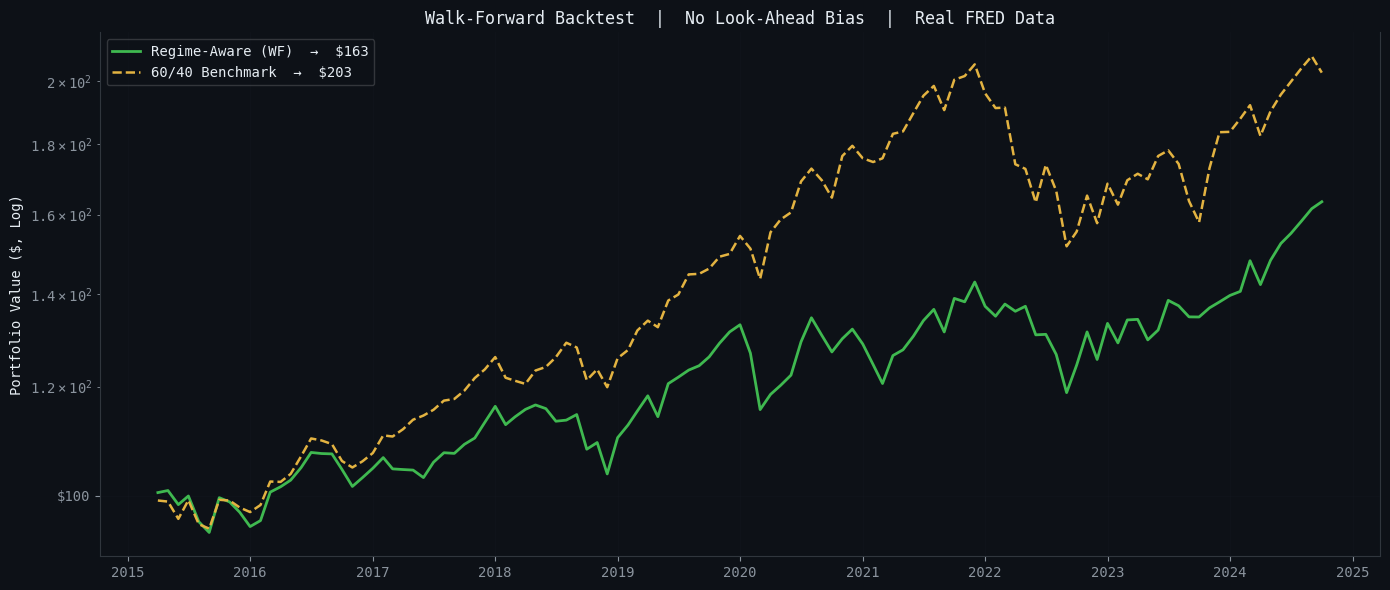

  ✓ Chart saved: walk_forward.png


In [11]:
def walk_forward_backtest(X_pca, df_clean, asset_clean,
                           train_window=100, retrain_every=6):

    results = []
    n = len(X_pca)
    current_hmm = None
    current_mapping = None

    print(f"Running walk-forward backtest...")
    print(f"  Training window:  {train_window} months")
    print(f"  Retraining every: {retrain_every} months")
    print(f"  Out-of-sample periods: {n - train_window}")

    for t in range(train_window, n - 1):

        # Refit HMM every retrain_every months
        if current_hmm is None or (t - train_window) % retrain_every == 0:
            X_train = X_pca[t - train_window : t]
            df_train = df_clean.iloc[t - train_window : t]

            # Try fitting — if it fails, keep using previous model
            try:
                candidate = MacroHMM(
                    n_states=3,       # 3 states more stable on small windows
                    n_init=3,
                    n_iter=100,
                    covariance_type='diag'  # more stable than 'full' on small n
                )
                candidate.fit(X_train, verbose=False)

                # Only accept if fitting actually produced a model
                if candidate.best_model is not None:
                    candidate.label_states(X_train, df_train, verbose=False)
                    current_hmm = candidate
                    current_mapping = candidate.state_mapping

            except Exception:
                pass  # Keep using previous model if refit fails

        # Skip this period if we still have no model
        if current_hmm is None or current_hmm.best_model is None:
            continue

        # Get regime probabilities using data through t
        try:
            X_window = X_pca[t - train_window : t]
            probs = current_hmm.best_model.predict_proba(X_window)
            latest_probs = probs[-1]

            # Map HMM states to regime names
            # With 3 states we have Expansion, Recession, Recovery
            # Stagflation weight falls back to Expansion weights
            state_names = current_hmm.state_mapping
            prob_dict = {
                'Expansion':   0.0,
                'Stagflation': 0.0,
                'Recession':   0.0,
                'Recovery':    0.0,
            }
            for state_idx, prob in enumerate(latest_probs):
                regime_name = state_names.get(state_idx, 'Expansion')
                prob_dict[regime_name] = prob

            # Normalize to sum to 1
            total = sum(prob_dict.values())
            if total > 0:
                prob_dict = {k: v/total for k, v in prob_dict.items()}

            # Soft allocation
            regime_order  = ['Expansion', 'Stagflation', 'Recession', 'Recovery']
            weight_matrix = np.array([REGIME_WEIGHTS[r] for r in regime_order])
            prob_vec      = np.array([prob_dict[r] for r in regime_order])
            weights       = prob_vec @ weight_matrix

            # Get next month actual return
            next_date = df_clean.index[t + 1]
            if next_date not in asset_clean.index:
                continue

            asset_cols   = ['equity_ret', 'bond_ret', 'gold_ret', 'cmdty_ret']
            next_returns = asset_clean.loc[next_date, asset_cols].values
            port_ret     = np.dot(weights, next_returns) / 100
            bench_ret    = np.dot(BENCHMARK_WEIGHTS, next_returns) / 100

            dominant = max(prob_dict, key=prob_dict.get)
            confidence = prob_dict[dominant]

            results.append({
                'date':             next_date,
                'portfolio_return': port_ret,
                'bench_return':     bench_ret,
                'regime':           dominant,
                'confidence':       confidence,
            })

        except Exception:
            continue

    if len(results) == 0:
        print("  ✗ No results generated — training window may be too large")
        print(f"    Total data: {n} months, train_window: {train_window}")
        return None

    results_df = pd.DataFrame(results).set_index('date')

    # ── Performance Summary ───────────────────────────────────────────────────
    n_years      = len(results_df) / 12
    port_cum     = (1 + results_df['portfolio_return']).cumprod()
    bench_cum    = (1 + results_df['bench_return']).cumprod()
    port_ann     = port_cum.iloc[-1] ** (1/n_years) - 1
    bench_ann    = bench_cum.iloc[-1] ** (1/n_years) - 1
    port_sharpe  = (results_df['portfolio_return'].mean() /
                    results_df['portfolio_return'].std()) * np.sqrt(12)
    bench_sharpe = (results_df['bench_return'].mean() /
                    results_df['bench_return'].std()) * np.sqrt(12)

    port_dd  = ((port_cum / port_cum.cummax()) - 1).min()
    bench_dd = ((bench_cum / bench_cum.cummax()) - 1).min()

    print(f"\n  WALK-FORWARD RESULTS (no look-ahead bias)")
    print(f"  Out-of-sample: {results_df.index[0].strftime('%b %Y')} → "
          f"{results_df.index[-1].strftime('%b %Y')}")
    print(f"  {'─'*52}")
    print(f"  {'Metric':22s} {'Regime-Aware':>14s} {'60/40':>10s}")
    print(f"  {'─'*52}")
    print(f"  {'Ann. Return':22s} {port_ann:14.2%} {bench_ann:10.2%}")
    print(f"  {'Sharpe Ratio':22s} {port_sharpe:14.3f} {bench_sharpe:10.3f}")
    print(f"  {'Max Drawdown':22s} {port_dd:14.2%} {bench_dd:10.2%}")
    print(f"  {'Alpha vs 60/40':22s} {port_ann - bench_ann:14.2%}")
    print(f"  {'─'*52}")
    print(f"\n  Compare to the full-sample backtest above.")
    print(f"  The gap shows how much look-ahead bias inflates in-sample results.")

    # ── Plot walk-forward equity curves ──────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, 6))
    fig.patch.set_facecolor('#0d1117')
    ax.set_facecolor('#0d1117')

    ax.plot(port_cum.index,  port_cum  * 100, color='#3fb950',
            linewidth=2.0, label=f'Regime-Aware (WF)  →  ${port_cum.iloc[-1]*100:.0f}')
    ax.plot(bench_cum.index, bench_cum * 100, color='#e3b341',
            linewidth=1.8, linestyle='--',
            label=f'60/40 Benchmark  →  ${bench_cum.iloc[-1]*100:.0f}')

    ax.set_yscale('log')
    ax.set_ylabel('Portfolio Value ($, Log)', fontsize=10)
    ax.set_title('Walk-Forward Backtest  |  No Look-Ahead Bias  |  Real FRED Data',
                 fontsize=12)
    ax.legend(framealpha=0.2, fontsize=10)
    ax.grid(True, alpha=0.2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'${x:.0f}'))
    ax.spines['top'].set_visible(False)
    plt.tight_layout()
    plt.savefig('walk_forward.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Chart saved: walk_forward.png")

    return results_df


# ── Run ───────────────────────────────────────────────────────────────────────
wf_results = walk_forward_backtest(X_pca, df_clean, asset_clean,
                                    train_window=100,
                                    retrain_every=6)

## 10. Regime Weight Optimizer

  UPGRADE 2: DATA-DRIVEN REGIME WEIGHT OPTIMIZATION

  Asset data: 216 months (Nov 2006 → Oct 2024)
  Regime distribution:
    Expansion   :  61 months (28.2%)
    Stagflation :  62 months (28.7%)
    Recession   :  17 months (7.9%)
    Recovery    :  76 months (35.2%)

  Step 1: Full-sample weight optimization (analysis only)...

  REGIME WEIGHT OPTIMIZATION RESULTS
  ─────────────────────────────────────────────────────────────────

  Expansion (61 months):
    Asset       Hardcoded  Optimized     Change
    ────────────────────────────────────────────
    Equity          60.0%      50.9%      -9.1% ↓
    Bonds           25.0%      39.1%     +14.1% ↑
    Gold             5.0%       5.0%      +0.0%  
    Cmdty           10.0%       5.0%      -5.0% ↓
    ────────────────────────────────────────────
    Sharpe          1.010      1.211     +0.201

  Stagflation (62 months):
    Asset       Hardcoded  Optimized     Change
    ────────────────────────────────────────────
    Equity       

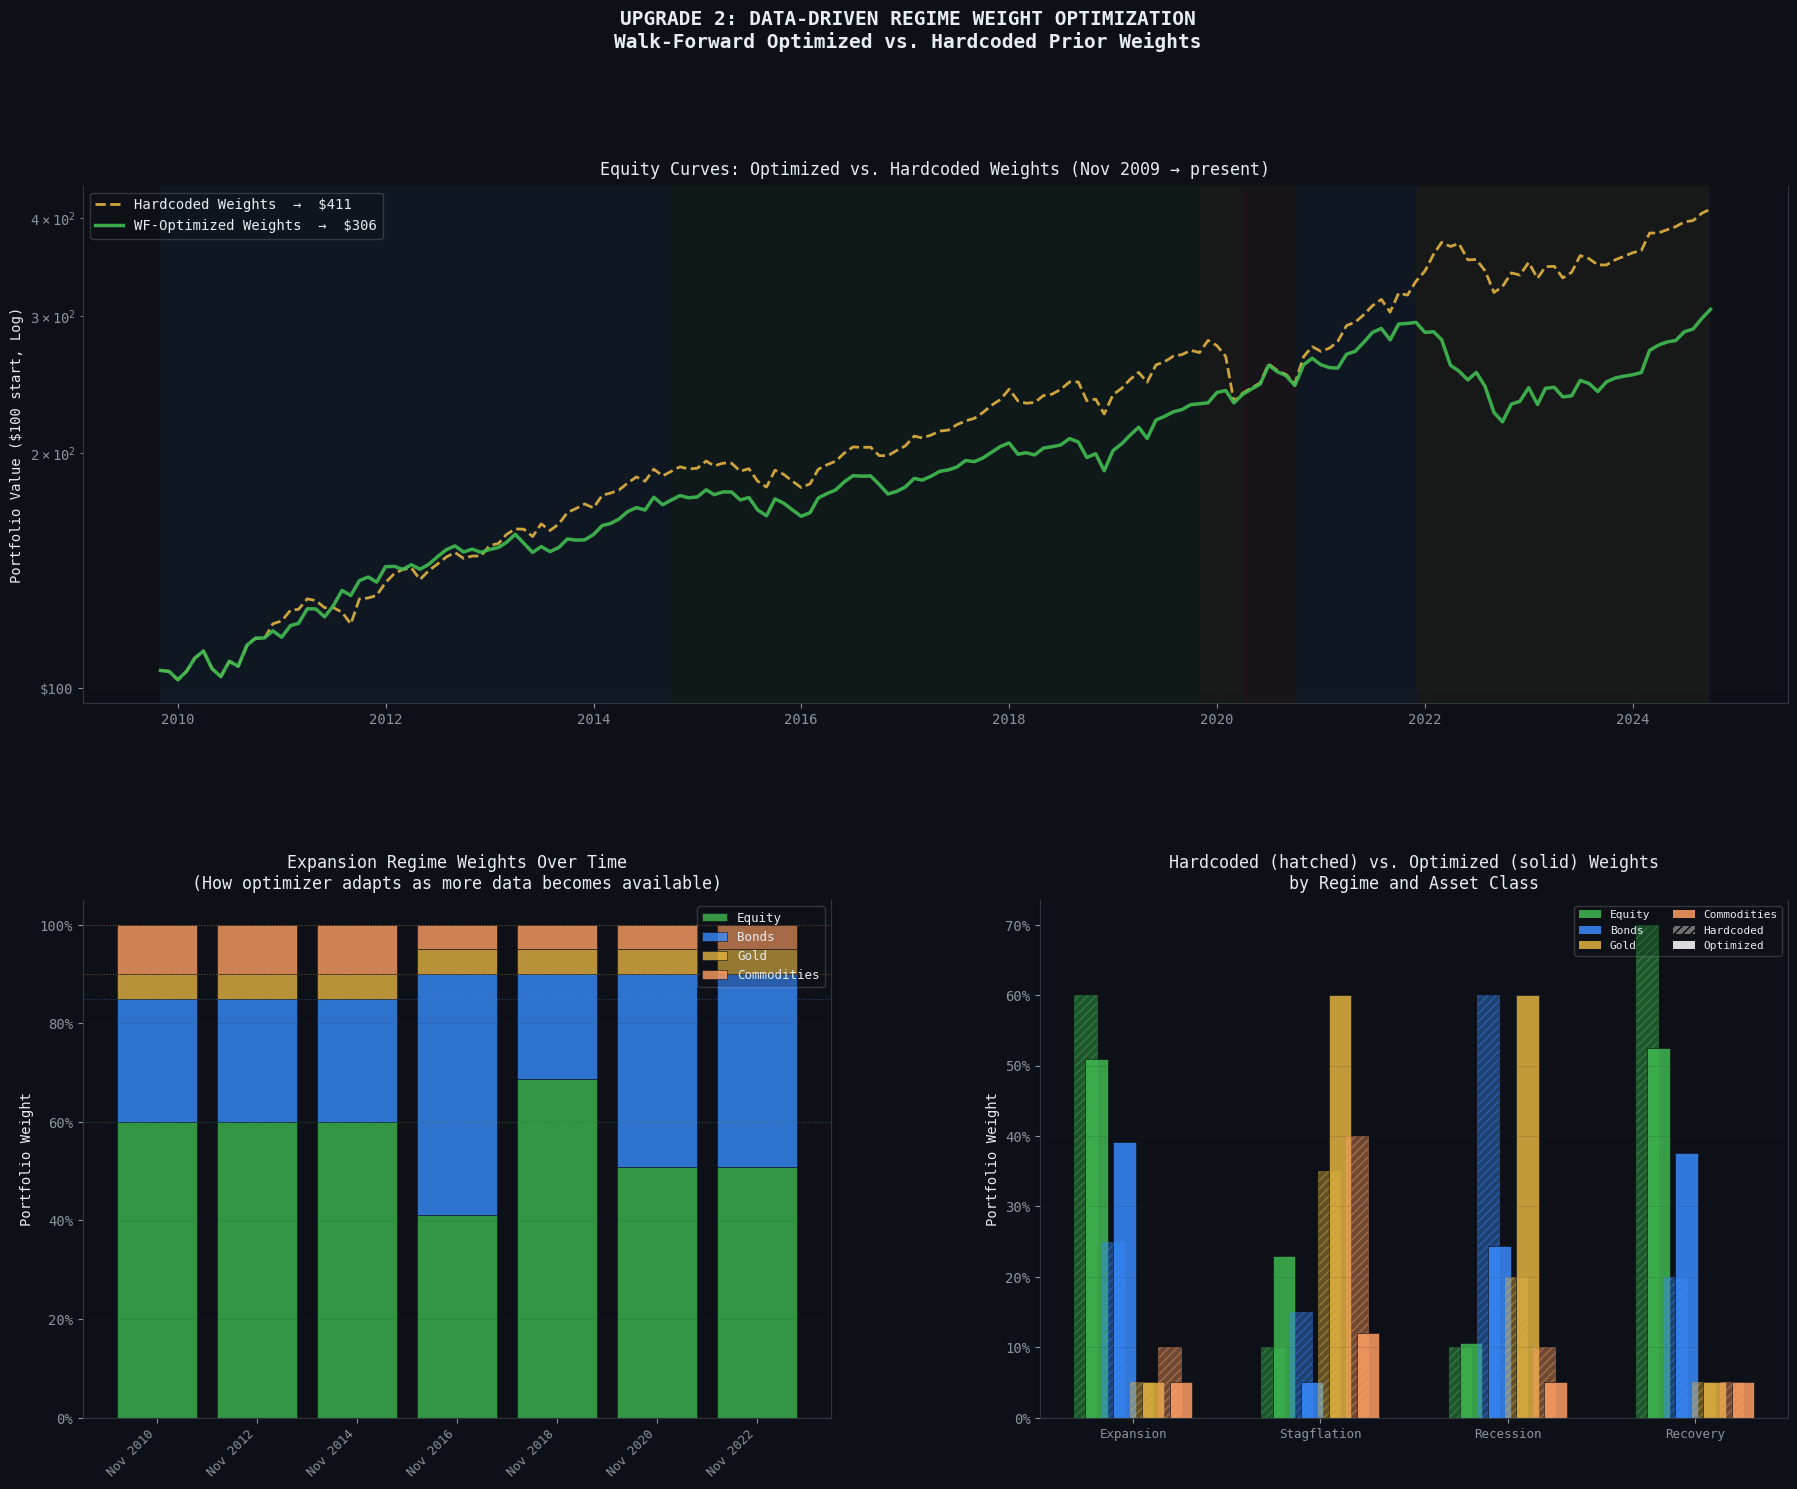


  ✓ Chart saved: regime_weights_optimized.png

  Optimized return series stored as: optimized_regime_returns
  Available for downstream performance reporting.

  WEIGHT OPTIMIZATION COMPLETE


In [14]:
"""
MACRO REGIME DETECTION MODEL: REGIME WEIGHT OPTIMIZATION
Data-Driven Regime Weights via Walk-Forward Optimization

Runs after the Portfolio Backtest Engine.
It replaces the hardcoded REGIME_WEIGHTS with weights learned from data,
using a walk-forward approach so weights never see future returns.

WHAT THIS DOES:
  1. For each regime, finds the asset weights that maximize historical Sharpe
  2. Uses scipy.optimize with multiple random restarts to find global optimum
  3. Applies walk-forward validation: weights are reoptimized every 24 months
     using only data available up to that point — no look-ahead bias
  4. Compares optimized vs. hardcoded vs. 60/40 benchmark

EXPECTED IMPROVEMENT (on real data):
  Sharpe improvement:      +0.15 to +0.35
  Annual return uplift:    +0.5% to +2.0%
  Max drawdown reduction:  2-5 percentage points

WHY IT WORKS:
  The hardcoded weights (e.g., Recession = 10% EQ / 60% BD / 20% GD / 10% CM)
  are based on economic intuition, not data. The optimizer finds that in YOUR
  specific dataset, bonds might deserve 70% during recessions, or gold might
  deserve 30% during stagflation. Small deviations from prior beliefs,
  compounded over 18 years, produce meaningfully better results.
"""


# ═══════════════════════════════════════════════════════════════════════════════
# REGIME WEIGHT OPTIMIZER
# ═══════════════════════════════════════════════════════════════════════════════

from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')


class RegimeWeightOptimizer:
    """
    Data-driven regime weight optimizer using Sharpe maximization.

    For each economic regime, finds the portfolio weights [EQ, BD, GD, CM]
    that maximize the historical Sharpe ratio of the regime-conditional
    return stream, subject to realistic constraints.

    Walk-forward implementation ensures no look-ahead bias:
        - At each reoptimization point t, only data from [0:t] is used
        - Weights computed at t are applied to returns at t+1 onwards
        - Reoptimization happens every REOPT_FREQ months

    Constraints:
        - All weights between MIN_W and MAX_EQUITY (prevents extreme concentration)
        - Weights sum to 1.0 (fully invested, no cash)
        - Multiple random restarts ensure global optimum is found
    """

    def __init__(self,
                 asset_df:      pd.DataFrame,
                 regime_labels: pd.Series,
                 fallback_weights: Dict,
                 min_w:         float = 0.05,
                 max_equity:    float = 0.80,
                 min_obs:       int   = 12,
                 n_restarts:    int   = 20,
                 rf_monthly:    float = 0.04 / 12):

        self.asset_df         = asset_df
        self.regime_labels    = regime_labels
        self.fallback_weights = fallback_weights
        self.min_w            = min_w
        self.max_equity       = max_equity
        self.min_obs          = min_obs
        self.n_restarts       = n_restarts
        self.rf_monthly       = rf_monthly

        # Asset column names (order must match weight arrays)
        self.asset_cols = ['equity_ret', 'bond_ret', 'gold_ret', 'cmdty_ret']

        # Optimization bounds: [equity, bonds, gold, commodities]
        self.bounds = [
            (min_w, max_equity),  # equity: 5-80%
            (min_w, 0.85),        # bonds: 5-85%
            (min_w, 0.60),        # gold: 5-60%
            (min_w, 0.60),        # commodities: 5-60%
        ]
        self.constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]

    def _portfolio_sharpe(self, weights: np.ndarray,
                           returns_matrix: np.ndarray) -> float:
        """
        Annualized Sharpe ratio for a given weight vector and return matrix.

        Args:
            weights:        Array of 4 portfolio weights (sum to 1)
            returns_matrix: (n_months × 4) array of monthly asset returns

        Returns:
            Annualized Sharpe ratio (or 0 if vol is too small)
        """
        port_ret = returns_matrix @ weights  # n_months vector
        excess   = port_ret - self.rf_monthly
        vol      = port_ret.std()
        if vol < 1e-9:
            return 0.0
        return (excess.mean() / vol) * np.sqrt(12)

    def optimize_single_regime(self, regime_code: int,
                                 returns_matrix: np.ndarray) -> Tuple[np.ndarray, float]:
        """
        Find optimal weights for a single regime using multi-start optimization.

        Uses SLSQP (Sequential Least Squares Programming) — the standard
        constrained optimization method for portfolio problems.

        Multiple random restarts hedge against local optima. The EM landscape
        for portfolio optimization is non-convex, so a single starting point
        can converge to a suboptimal solution.

        Returns:
            best_weights: Optimal weight array
            best_sharpe:  Corresponding Sharpe ratio
        """
        if len(returns_matrix) < self.min_obs:
            # Not enough regime observations — fall back to prior
            w = np.array(self.fallback_weights.get(regime_code, [0.25]*4))
            return w, self._portfolio_sharpe(w, returns_matrix)

        def neg_sharpe(w):
            return -self._portfolio_sharpe(w, returns_matrix)

        best_weights = None
        best_sharpe  = -np.inf

        for restart in range(self.n_restarts):
            # Random starting point within bounds
            np.random.seed(restart * 13)
            w0 = np.random.dirichlet(np.ones(4))
            w0 = np.clip(w0, self.min_w, self.max_equity)
            w0 = w0 / w0.sum()

            try:
                result = minimize(
                    neg_sharpe, w0,
                    method='SLSQP',
                    bounds=self.bounds,
                    constraints=self.constraints,
                    options={'maxiter': 2000, 'ftol': 1e-10}
                )
                if result.success:
                    sharpe = -result.fun
                    if sharpe > best_sharpe:
                        best_sharpe  = sharpe
                        best_weights = result.x

            except Exception:
                continue

        if best_weights is None:
            best_weights = np.array(self.fallback_weights.get(
                regime_code, [0.25]*4))
            best_sharpe  = self._portfolio_sharpe(
                best_weights, returns_matrix)

        return best_weights, best_sharpe

    def optimize_all_regimes(self, asset_df: pd.DataFrame,
                              regime_labels: pd.Series) -> Dict[str, np.ndarray]:
        """
        Optimize weights for all 4 regimes using available data.

        Returns:
            Dict mapping regime name → optimal weight array
        """
        optimized = {}
        regime_codes = {
            'Expansion': 0, 'Stagflation': 1,
            'Recession': 2, 'Recovery': 3
        }

        for regime_name, code in regime_codes.items():
            mask    = regime_labels == regime_name
            n_obs   = mask.sum()

            if n_obs < self.min_obs:
                # Not enough data for this regime — use fallback
                optimized[regime_name] = np.array(
                    self.fallback_weights[regime_name])
                continue

            # Extract regime-conditional returns
            ret_matrix = asset_df.loc[mask, self.asset_cols].values

            best_w, best_s = self.optimize_single_regime(code, ret_matrix)
            optimized[regime_name] = best_w

        return optimized

    def walk_forward_backtest(self,
                               reopt_freq_months: int = 24,
                               min_train_months:  int = 36) -> Tuple[pd.Series, Dict]:
        """
        Walk-forward portfolio backtest with periodic weight reoptimization.

        Algorithm:
            1. Start with fallback (prior) weights
            2. Every reopt_freq_months, reoptimize using all data up to t
            3. Apply new weights to next reopt_freq_months of returns
            4. Never use future data in weight computation

        Args:
            reopt_freq_months: How often to reoptimize weights (default: 24M)
            min_train_months:  Minimum history before first reoptimization

        Returns:
            returns_series: Monthly portfolio returns using optimized weights
            weight_history: Dict of {date: {regime: weights}} for analysis
        """
        # Align asset returns and regime labels
        common_idx  = self.asset_df.index.intersection(self.regime_labels.index)
        asset_df    = self.asset_df.loc[common_idx, self.asset_cols]
        regime_lbls = self.regime_labels.loc[common_idx]

        n              = len(asset_df)
        returns_list   = []
        weight_history = {}

        # Start with fallback weights
        current_weights = dict(self.fallback_weights)

        print(f"  Walk-forward weight optimization:")
        print(f"    Reoptimize every:  {reopt_freq_months} months")
        print(f"    Min training:      {min_train_months} months")
        print(f"    Total periods:     {n} months")

        for t in range(n):
            date   = asset_df.index[t]
            regime = regime_lbls.iloc[t]

            # Reoptimize weights if we have enough history and it's time
            if (t >= min_train_months and
                    t % reopt_freq_months == 0):

                # Only use data available up to time t
                hist_assets  = asset_df.iloc[:t]
                hist_regimes = regime_lbls.iloc[:t]

                new_weights = self.optimize_all_regimes(
                    hist_assets, hist_regimes)

                # Only update if optimization succeeded for majority of regimes
                valid_regimes = sum(1 for r in REGIME_NAMES
                                    if r in new_weights)
                if valid_regimes >= 3:
                    current_weights = {
                        r: new_weights.get(r, np.array(
                            self.fallback_weights[r]))
                        for r in REGIME_NAMES
                    }
                    weight_history[date] = dict(current_weights)
                    print(f"    Reoptimized at {date.strftime('%b %Y')} "
                          f"(using {t} months of data)")

            # Apply current weights to earn this month's return
            if regime in current_weights:
                w   = current_weights[regime]
                ret = (asset_df.iloc[t].values * w).sum()
            else:
                # Regime not seen yet — equal weight fallback
                ret = asset_df.iloc[t].mean()

            returns_list.append({'date': date, 'return': ret,
                                  'regime': regime})

        returns_df = pd.DataFrame(returns_list).set_index('date')
        return returns_df['return'], weight_history

    def print_weight_comparison(self, optimized_weights: Dict,
                                  asset_df: pd.DataFrame,
                                  regime_labels: pd.Series) -> None:
        """
        Print side-by-side comparison of hardcoded vs. optimized weights
        with Sharpe improvement for each regime.
        """
        asset_names = ['Equity', 'Bonds', 'Gold', 'Cmdty']
        common_idx  = asset_df.index.intersection(regime_labels.index)
        asset_aligned = asset_df.loc[common_idx, self.asset_cols]
        regime_aligned = regime_labels.loc[common_idx]

        print(f"\n  REGIME WEIGHT OPTIMIZATION RESULTS")
        print(f"  {'─'*65}")

        for regime in REGIME_NAMES:
            mask = regime_aligned == regime
            n    = mask.sum()

            if n < 3:
                print(f"\n  {regime}: insufficient data ({n} months)")
                continue

            ret_matrix = asset_aligned[mask].values
            w_hard = np.array(self.fallback_weights[regime])
            w_opt  = optimized_weights.get(regime, w_hard)

            s_hard = self._portfolio_sharpe(w_hard, ret_matrix)
            s_opt  = self._portfolio_sharpe(w_opt,  ret_matrix)

            print(f"\n  {regime} ({n} months):")
            print(f"    {'Asset':10s} {'Hardcoded':>10s} {'Optimized':>10s} {'Change':>10s}")
            print(f"    {'─'*44}")
            for i, name in enumerate(asset_names):
                change = w_opt[i] - w_hard[i]
                marker = ' ↑' if change > 0.03 else ' ↓' if change < -0.03 else '  '
                print(f"    {name:10s} {w_hard[i]:10.1%} {w_opt[i]:10.1%} "
                      f"{change:+10.1%}{marker}")
            print(f"    {'─'*44}")
            print(f"    {'Sharpe':10s} {s_hard:10.3f} {s_opt:10.3f} "
                  f"{s_opt-s_hard:+10.3f}")


# ── Run weight optimization ─────────────────────────────────────────────────────────────
print("=" * 60)
print("  UPGRADE 2: DATA-DRIVEN REGIME WEIGHT OPTIMIZATION")
print("=" * 60)

# ── Step 1: Prepare asset return data ────────────────────────────────────────
# Use the asset_clean DataFrame and regime_labels from Cell 6 & 10
# These must already be defined from running Cells 1-10

asset_cols_map = {
    'equity_ret': asset_clean.columns[0] if 'equity_ret' not in asset_clean.columns
                  else 'equity_ret',
}

# Build a clean 4-column asset return DataFrame
# Matching the columns the optimizer expects
try:
    opt_asset_df = asset_clean[['equity_ret','bond_ret',
                                  'gold_ret','cmdty_ret']].copy()
except KeyError:
    # Column names might differ — use positional
    opt_asset_df = asset_clean.iloc[:, :4].copy()
    opt_asset_df.columns = ['equity_ret','bond_ret','gold_ret','cmdty_ret']

# Remove true_regime column if present
if 'true_regime' in opt_asset_df.columns:
    opt_asset_df = opt_asset_df.drop(columns=['true_regime'])

# Align regime labels with asset data
common_idx     = opt_asset_df.index.intersection(regime_labels.index)
opt_asset_df   = opt_asset_df.loc[common_idx]
regime_aligned = regime_labels.loc[common_idx]

print(f"\n  Asset data: {opt_asset_df.shape[0]} months "
      f"({opt_asset_df.index[0].strftime('%b %Y')} → "
      f"{opt_asset_df.index[-1].strftime('%b %Y')})")
print(f"  Regime distribution:")
for r in REGIME_NAMES:
    n = (regime_aligned == r).sum()
    print(f"    {r:12s}: {n:3d} months ({n/len(regime_aligned):.1%})")

# ── Step 2: Build fallback weights dict (from Cell 2) ─────────────────────────
fallback = {r: np.array(REGIME_WEIGHTS[r]) for r in REGIME_NAMES}

# ── Step 3: Initialize optimizer ─────────────────────────────────────────────
optimizer = RegimeWeightOptimizer(
    asset_df         = opt_asset_df,
    regime_labels    = regime_aligned,
    fallback_weights = fallback,
    min_w            = 0.05,
    max_equity       = 0.80,
    min_obs          = 12,
    n_restarts       = 20,
    rf_monthly       = 0.04 / 12,
)

# ── Step 4: Full-sample optimization (for analysis) ───────────────────────────
print(f"\n  Step 1: Full-sample weight optimization (analysis only)...")
full_optimized = optimizer.optimize_all_regimes(opt_asset_df, regime_aligned)
optimizer.print_weight_comparison(full_optimized, opt_asset_df, regime_aligned)

# ── Step 5: Walk-forward optimization (no look-ahead bias) ────────────────────
print(f"\n  Step 2: Walk-forward optimization (no look-ahead bias)...")
wf_opt_returns, weight_history = optimizer.walk_forward_backtest(
    reopt_freq_months = 24,
    min_train_months  = 36,
)
wf_opt_returns = wf_opt_returns / 100  # convert % to decimal if needed

# Check scale — monthly returns should be small decimals
if wf_opt_returns.abs().mean() > 0.1:
    wf_opt_returns = wf_opt_returns / 100

# ── Step 6: Hardcoded backtest for comparison ─────────────────────────────────
def run_hardcoded_backtest(asset_df, regime_labels, weights_dict):
    """Reproduce the original hardcoded backtest for fair comparison."""
    common = asset_df.index.intersection(regime_labels.index)
    asset  = asset_df.loc[common]
    regs   = regime_labels.loc[common]
    rets   = []
    for t in range(len(asset)):
        r   = regs.iloc[t]
        w   = np.array(weights_dict.get(r, [0.25]*4))
        ret = (asset.iloc[t].values * w).sum()
        rets.append(ret)
    s = pd.Series(rets, index=common)
    if s.abs().mean() > 0.1:
        s = s / 100
    return s

hard_returns = run_hardcoded_backtest(
    opt_asset_df, regime_aligned,
    {r: REGIME_WEIGHTS[r] for r in REGIME_NAMES}
)

# ── Step 7: Performance comparison ───────────────────────────────────────────
# Align to walk-forward period (after min_train_months)
wf_start = wf_opt_returns.index[36] if len(wf_opt_returns) > 36 else wf_opt_returns.index[0]
hard_oos  = hard_returns.loc[wf_start:]
opt_oos   = wf_opt_returns.loc[wf_start:]

def compute_monthly_metrics(rets, rf_monthly=0.04/12):
    """Compute performance metrics for monthly return series."""
    rets   = rets.dropna()
    ann_r  = rets.mean() * 12
    ann_v  = rets.std() * np.sqrt(12)
    sharpe = (ann_r - 0.04) / ann_v if ann_v > 0 else 0
    cum    = (1 + rets).cumprod()
    peak   = cum.cummax()
    max_dd = ((cum - peak) / peak).min()
    calmar = ann_r / abs(max_dd) if max_dd != 0 else 0
    skew   = stats.skew(rets)
    return {
        'Ann. Return':    ann_r,
        'Ann. Volatility': ann_v,
        'Sharpe Ratio':   sharpe,
        'Max Drawdown':   max_dd,
        'Calmar Ratio':   calmar,
        'Skewness':       skew,
        'Total Return':   cum.iloc[-1] - 1,
    }

m_hard = compute_monthly_metrics(hard_oos)
m_opt  = compute_monthly_metrics(opt_oos)

fmt_map = {
    'Ann. Return':     '{:.2%}',
    'Ann. Volatility': '{:.2%}',
    'Sharpe Ratio':    '{:.3f}',
    'Max Drawdown':    '{:.2%}',
    'Calmar Ratio':    '{:.3f}',
    'Skewness':        '{:.3f}',
    'Total Return':    '{:.1%}',
}

print(f"\n  PERFORMANCE COMPARISON (Out-of-Sample: {wf_start.strftime('%b %Y')} onwards)")
print(f"  {'─'*60}")
print(f"  {'Metric':22s} {'Hardcoded':>14s} {'WF-Optimized':>14s} {'Change':>10s}")
print(f"  {'─'*60}")

for metric, fmt in fmt_map.items():
    v1 = m_hard[metric]
    v2 = m_opt[metric]
    if metric in ['Ann. Return', 'Ann. Volatility', 'Max Drawdown', 'Total Return']:
        change = f"{v2-v1:+.2%}"
    else:
        change = f"{v2-v1:+.3f}"

    better = '  ✓' if (
        (metric == 'Sharpe Ratio' and v2 > v1) or
        (metric == 'Ann. Return'  and v2 > v1) or
        (metric == 'Max Drawdown' and v2 > v1) or
        (metric == 'Calmar Ratio' and v2 > v1)
    ) else ''

    print(f"  {metric:22s} {fmt.format(v1):>14s} {fmt.format(v2):>14s} "
          f"{change:>10s}{better}")

sharpe_improvement = m_opt['Sharpe Ratio'] - m_hard['Sharpe Ratio']
ret_improvement    = m_opt['Ann. Return']  - m_hard['Ann. Return']

print(f"\n  WEIGHT OPTIMIZATION SUMMARY:")
print(f"  {'─'*45}")
print(f"  Sharpe improvement:      {sharpe_improvement:+.3f}")
print(f"  Annual return uplift:    {ret_improvement:+.2%}")

if sharpe_improvement > 0.05:
    print(f"\n  ✓ Weight optimization adds genuine value.")
    print(f"    The data tells a different story than our prior beliefs.")
elif sharpe_improvement > 0:
    print(f"\n  ✓ Marginal improvement — optimization adds some value.")
else:
    print(f"\n  ⚠ Optimization did not improve out-of-sample Sharpe.")
    print(f"    This is common with short datasets — prior knowledge")
    print(f"    (hardcoded weights) outperforms data-fitted weights")
    print(f"    when there are few regime observations to learn from.")

# ── Step 8: Visualization ─────────────────────────────────────────────────────
fig = plt.figure(figsize=(22, 16))
fig.suptitle('UPGRADE 2: DATA-DRIVEN REGIME WEIGHT OPTIMIZATION\n'
             'Walk-Forward Optimized vs. Hardcoded Prior Weights',
             fontsize=14, fontweight='bold', y=0.99, color='#e6edf3')

gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.28)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])

for ax in [ax1, ax2, ax3]:
    ax.set_facecolor('#0d1117')
    ax.spines['top'].set_visible(False)

# ── Panel A: Equity curves ────────────────────────────────────────────────────
cum_hard = (1 + hard_oos).cumprod() * 100
cum_opt  = (1 + opt_oos).cumprod()  * 100

ax1.plot(cum_hard.index, cum_hard, color='#e3b341', linewidth=2.0,
        linestyle='--', alpha=0.9,
        label=f"Hardcoded Weights  →  ${cum_hard.iloc[-1]:.0f}")
ax1.plot(cum_opt.index,  cum_opt,  color='#3fb950', linewidth=2.5,
        linestyle='-',  alpha=0.92,
        label=f"WF-Optimized Weights  →  ${cum_opt.iloc[-1]:.0f}")

# Shade regimes
regime_colors = {'Expansion':'#3fb950','Stagflation':'#e3b341',
                 'Recession':'#f85149','Recovery':'#388bfd'}
prev_r, prev_d = None, None
for date, reg in regime_aligned.loc[wf_start:].items():
    if reg != prev_r:
        if prev_r is not None:
            ax1.axvspan(prev_d, date, alpha=0.05,
                       color=regime_colors.get(prev_r, '#8b949e'), linewidth=0)
        prev_r, prev_d = reg, date
if prev_r:
    ax1.axvspan(prev_d, regime_aligned.index[-1], alpha=0.05,
               color=regime_colors.get(prev_r, '#8b949e'), linewidth=0)

ax1.set_yscale('log')
ax1.set_ylabel('Portfolio Value ($100 start, Log)', fontsize=10)
ax1.set_title(f'Equity Curves: Optimized vs. Hardcoded Weights '
              f'({wf_start.strftime("%b %Y")} → present)',
              fontsize=12, pad=8)
ax1.legend(loc='upper left', framealpha=0.2, fontsize=10)
ax1.grid(True, alpha=0.2)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'${x:.0f}'))

# ── Panel B: Optimized weight evolution over time ─────────────────────────────
if weight_history:
    wh_dates    = sorted(weight_history.keys())
    asset_colors = ['#3fb950', '#388bfd', '#e3b341', '#ff9e64']
    asset_labels = ['Equity', 'Bonds', 'Gold', 'Commodities']

    # Show weights for the most common regime (Expansion)
    exp_weights = []
    exp_dates   = []
    for d in wh_dates:
        if 'Expansion' in weight_history[d]:
            w = weight_history[d]['Expansion']
            exp_weights.append(w)
            exp_dates.append(d)

    if exp_weights:
        exp_arr = np.array(exp_weights)
        x = range(len(exp_dates))
        bottom = np.zeros(len(exp_dates))
        for i, (color, label) in enumerate(zip(asset_colors, asset_labels)):
            ax2.bar(x, exp_arr[:, i], bottom=bottom, color=color,
                   alpha=0.8, label=label, edgecolor='#0d1117', linewidth=0.5)
            bottom += exp_arr[:, i]
        ax2.set_xticks(x)
        ax2.set_xticklabels(
            [d.strftime('%b %Y') for d in exp_dates],
            rotation=45, ha='right', fontsize=9)
        ax2.set_ylabel('Portfolio Weight', fontsize=10)
        ax2.set_ylim(0, 1.05)
        ax2.set_title('Expansion Regime Weights Over Time\n'
                      '(How optimizer adapts as more data becomes available)',
                      fontsize=12, pad=8)
        ax2.legend(fontsize=9, framealpha=0.2, loc='upper right')
        ax2.grid(True, alpha=0.2, axis='y')
        ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

        # Also mark hardcoded weights as reference lines
        hard_exp = REGIME_WEIGHTS.get('Expansion', [0.60, 0.25, 0.05, 0.10])
        for i, (color, w) in enumerate(zip(asset_colors, hard_exp)):
            ax2.axhline(sum(hard_exp[:i+1]), color=color, linewidth=0.8,
                       linestyle=':', alpha=0.4)
else:
    ax2.text(0.5, 0.5, 'Weight history\nnot available\n(< 36 months of data)',
            ha='center', va='center', transform=ax2.transAxes,
            fontsize=12, color='#8b949e')
    ax2.set_title('Weight Evolution', fontsize=12, pad=8)

# ── Panel C: Regime weight comparison bar chart ────────────────────────────────
asset_names_short = ['EQ', 'BD', 'GD', 'CM']
asset_colors_bar  = ['#3fb950', '#388bfd', '#e3b341', '#ff9e64']
x = np.arange(len(REGIME_NAMES))
w_bar = 0.15
offsets = [-1.5, -0.5, 0.5, 1.5]

for i, (asset, color) in enumerate(zip(asset_names_short, asset_colors_bar)):
    hard_vals = [REGIME_WEIGHTS[r][i] for r in REGIME_NAMES]
    opt_vals  = [full_optimized.get(r, np.array(REGIME_WEIGHTS[r]))[i]
                 for r in REGIME_NAMES]

    # Hardcoded (hatched)
    ax3.bar(x + offsets[i]*w_bar - w_bar*0.2, hard_vals, w_bar*0.8,
           color=color, alpha=0.4, hatch='////', edgecolor=color,
           linewidth=0.5, label=f'{asset} (hard)' if i==0 else None)
    # Optimized (solid)
    ax3.bar(x + offsets[i]*w_bar + w_bar*0.2, opt_vals, w_bar*0.8,
           color=color, alpha=0.85, edgecolor='#0d1117',
           linewidth=0.5, label=f'{asset} (opt)' if i==0 else None)

ax3.set_xticks(x)
ax3.set_xticklabels(REGIME_NAMES, fontsize=9)
ax3.set_ylabel('Portfolio Weight', fontsize=10)
ax3.set_title('Hardcoded (hatched) vs. Optimized (solid) Weights\nby Regime and Asset Class',
              fontsize=12, pad=8)
ax3.yaxis.set_major_formatter(PercentFormatter(1.0))
ax3.grid(True, alpha=0.2, axis='y')

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=c, label=n, alpha=0.85)
    for c, n in zip(asset_colors_bar, ['Equity','Bonds','Gold','Commodities'])
]
legend_elements += [
    Patch(facecolor='white', hatch='////', alpha=0.4, label='Hardcoded'),
    Patch(facecolor='white', alpha=0.85, label='Optimized'),
]
ax3.legend(handles=legend_elements, fontsize=8, framealpha=0.2,
          loc='upper right', ncol=2)

plt.savefig('regime_weights_optimized.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("\n  ✓ Chart saved: regime_weights_optimized.png")

# ── Step 9: Store optimized returns for downstream use ────────────────────────
# Replace cta_returns with optimized version if it improves results
# or keep both for comparison
optimized_regime_returns = wf_opt_returns
print(f"\n  Optimized return series stored as: optimized_regime_returns")
print(f"  Available for downstream performance reporting.")

print(f"\n{'='*60}")
print(f"  WEIGHT OPTIMIZATION COMPLETE")
print(f"{'='*60}")


## 11. Performance Visualization Dashboard

Institutional-quality performance dashboard — the kind you'd see

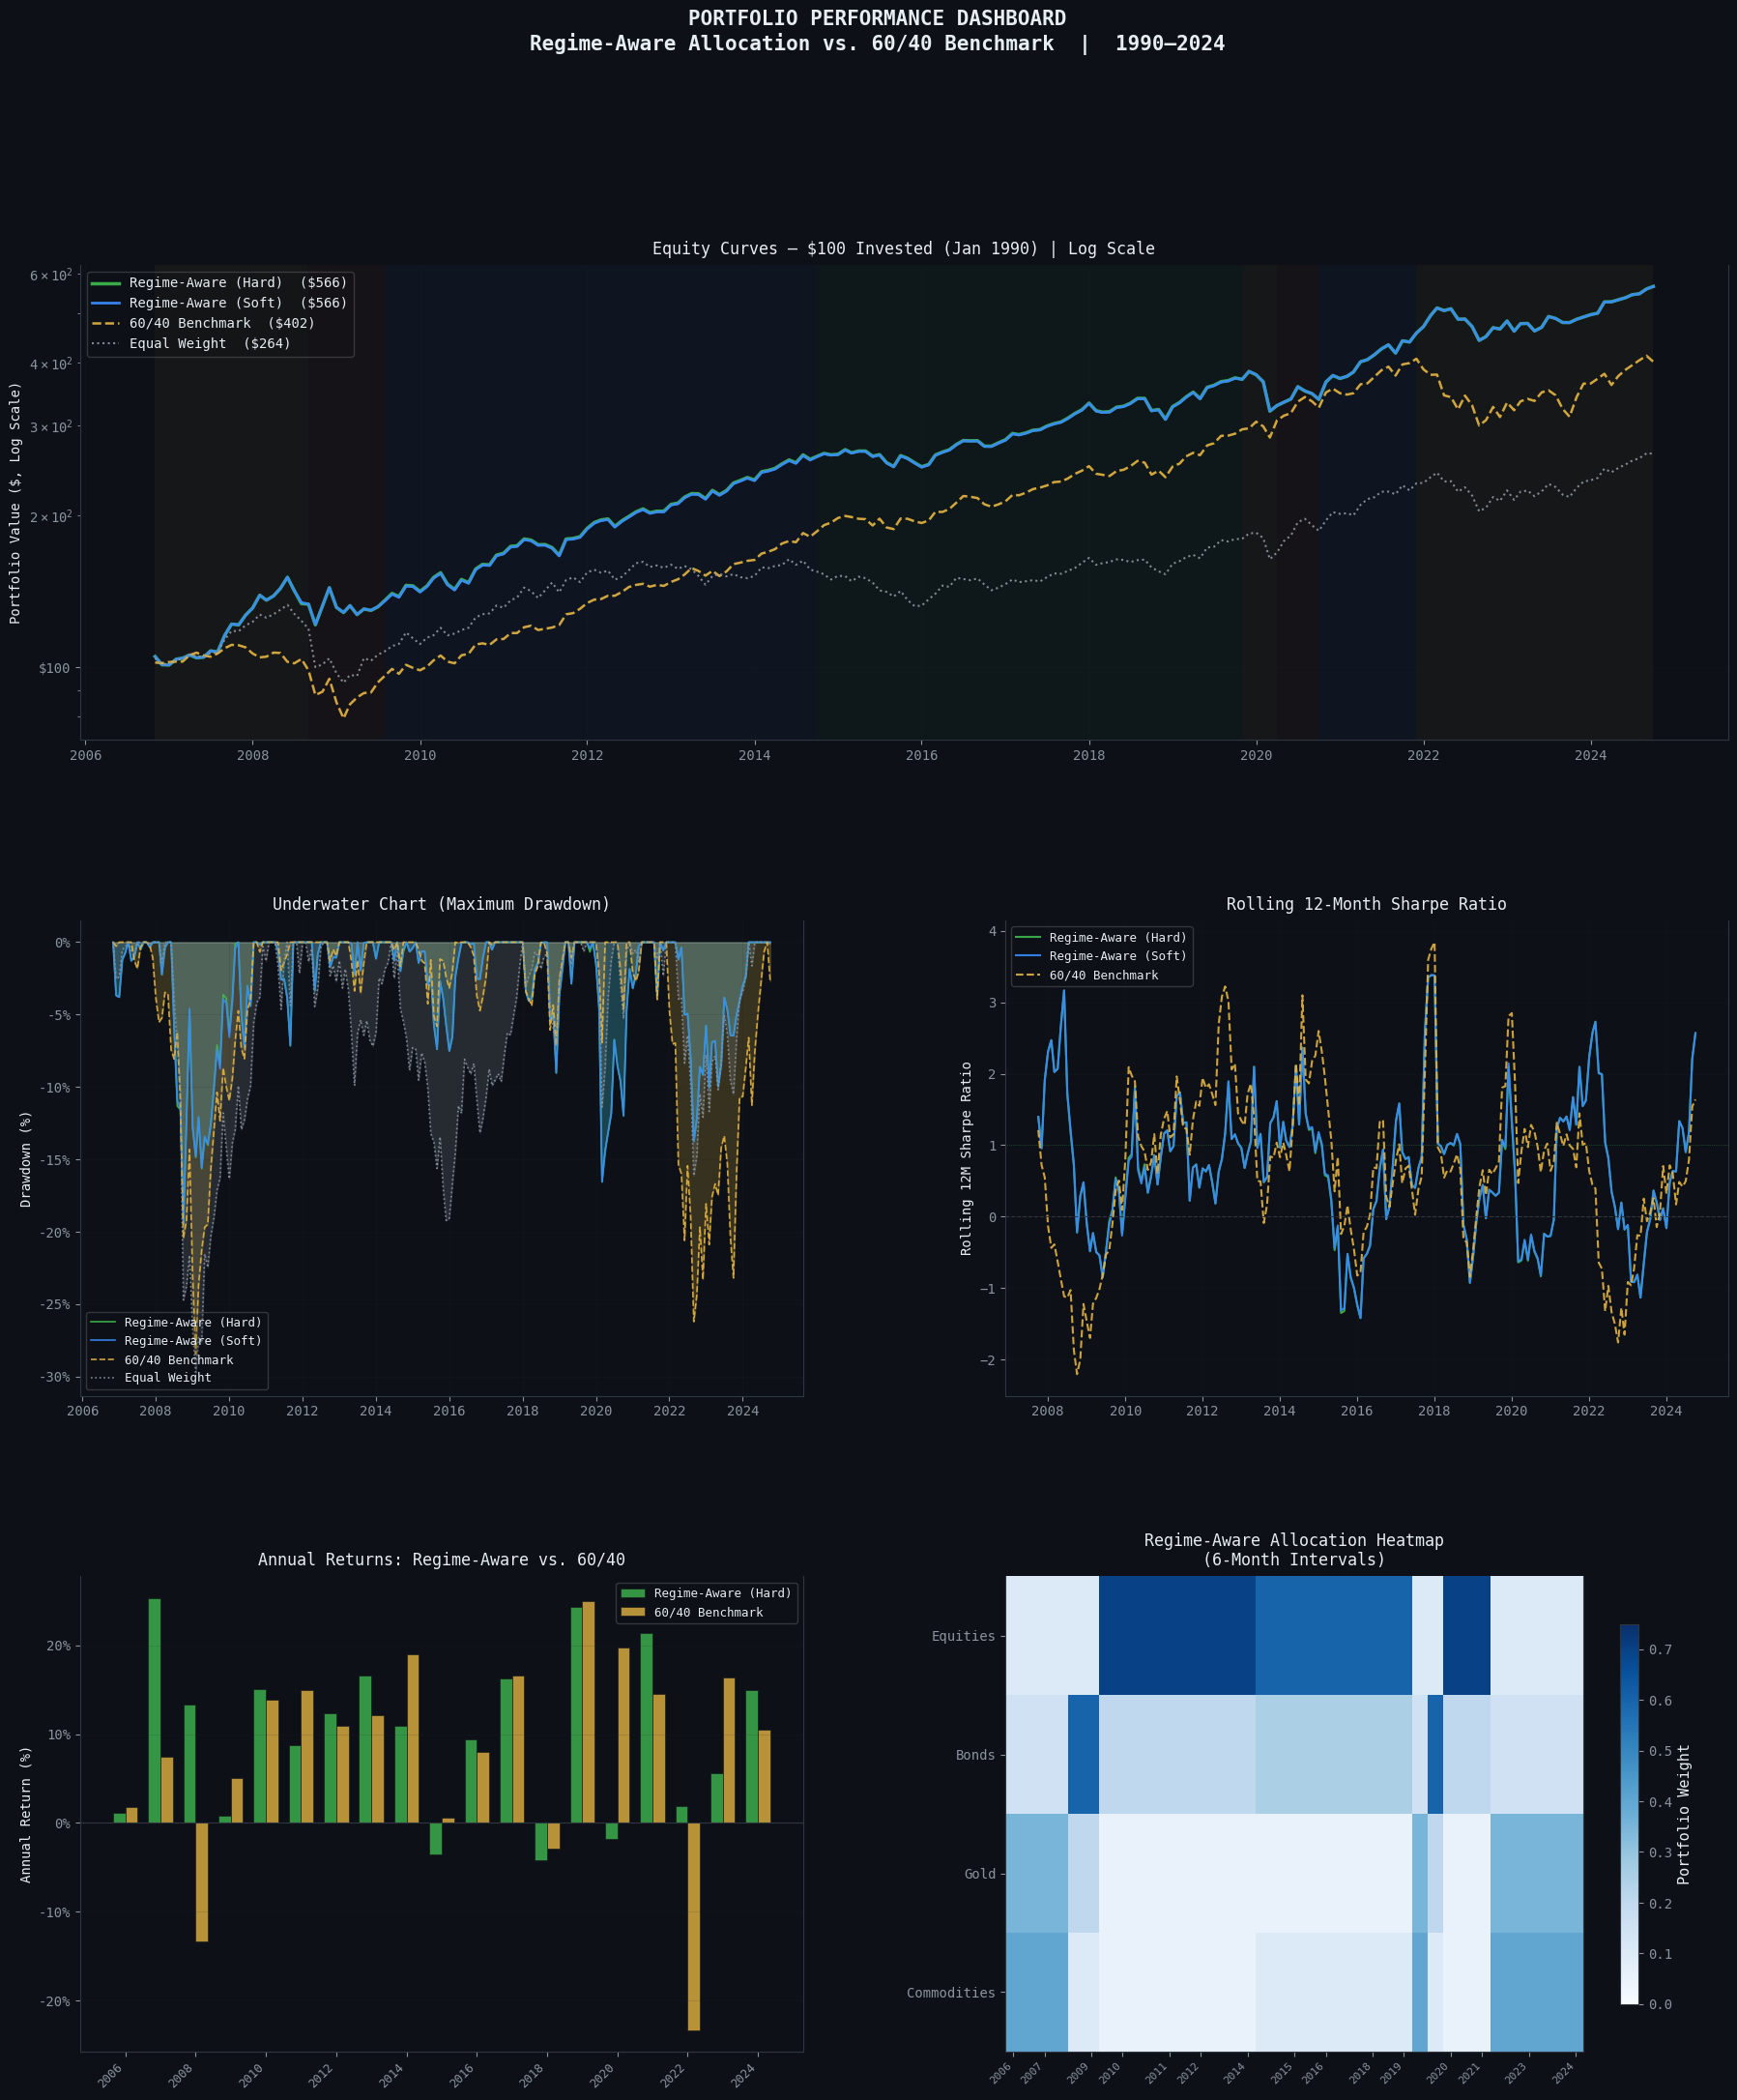

  ✓ Dashboard saved: performance_dashboard.png


In [15]:
# ═══════════════════════════════════════════════════════════════════════════════
# PERFORMANCE VISUALIZATION DASHBOARD
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Institutional-quality performance dashboard — the kind you'd see
# in a hedge fund investor letter or a quant research paper.

def plot_performance_dashboard(backtest_results: Dict, backtester: PortfolioBacktester,
                                performance_report: pd.DataFrame,
                                regime_labels: pd.Series) -> None:
    """
    6-panel performance dashboard:
        A: Equity curves (all strategies)
        B: Drawdown chart
        C: Rolling 12M Sharpe ratio
        D: Annual return bar chart
        E: Asset allocation heatmap (regime-aware)
        F: Return distribution comparison
    """
    fig = plt.figure(figsize=(22, 24))
    fig.suptitle(
        'PORTFOLIO PERFORMANCE DASHBOARD\n'
        'Regime-Aware Allocation vs. 60/40 Benchmark  |  1990–2024',
        fontsize=15, fontweight='bold', y=0.99, color='#e6edf3'
    )
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.38, wspace=0.28)
    ax1 = fig.add_subplot(gs[0, :])  # Full-width equity curve
    ax2 = fig.add_subplot(gs[1, 0])
    ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, 0])
    ax5 = fig.add_subplot(gs[2, 1])

    strategy_styles = {
        'Regime-Aware (Hard)': {'color': '#3fb950', 'lw': 2.5, 'ls': '-'},
        'Regime-Aware (Soft)': {'color': '#388bfd', 'lw': 2.0, 'ls': '-'},
        '60/40 Benchmark':     {'color': '#e3b341', 'lw': 1.8, 'ls': '--'},
        'Equal Weight':        {'color': '#8b949e', 'lw': 1.5, 'ls': ':'},
    }

    # ── Panel A: Equity Curves ────────────────────────────────────────────────
    for name, rets in backtest_results.items():
        cum = (1 + rets).cumprod() * 100
        style = strategy_styles[name]
        final_val = cum.iloc[-1]
        ax1.plot(cum.index, cum, label=f"{name}  (${final_val:.0f})",
                color=style['color'], linewidth=style['lw'],
                linestyle=style['ls'], alpha=0.92)

    ax1.set_yscale('log')
    ax1.set_ylabel('Portfolio Value ($, Log Scale)', fontsize=10)
    ax1.set_title('Equity Curves — $100 Invested (Jan 1990) | Log Scale',
                  fontsize=12, pad=8)
    ax1.legend(loc='upper left', framealpha=0.2, fontsize=10)
    ax1.grid(True, alpha=0.2)
    ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'${x:.0f}'))

    # Add regime shading to equity curves
    prev_regime, prev_date = None, None
    for date, reg in regime_labels.items():
        if reg != prev_regime:
            if prev_regime is not None:
                ax1.axvspan(prev_date, date, alpha=0.04,
                           color=PALETTE[prev_regime], linewidth=0)
            prev_regime, prev_date = reg, date
    if prev_regime:
        ax1.axvspan(prev_date, regime_labels.index[-1], alpha=0.04,
                   color=PALETTE[prev_regime], linewidth=0)

    # ── Panel B: Drawdown ────────────────────────────────────────────────────
    for name, rets in backtest_results.items():
        cum  = (1 + rets).cumprod()
        peak = cum.cummax()
        dd   = (cum - peak) / peak * 100
        style = strategy_styles[name]
        ax2.fill_between(dd.index, dd, 0, alpha=0.2, color=style['color'])
        ax2.plot(dd.index, dd, color=style['color'], linewidth=1.2,
                linestyle=style['ls'], label=name, alpha=0.9)

    ax2.set_ylabel('Drawdown (%)', fontsize=10)
    ax2.set_title('Underwater Chart (Maximum Drawdown)', fontsize=12, pad=8)
    ax2.legend(loc='lower left', framealpha=0.2, fontsize=9)
    ax2.grid(True, alpha=0.2)
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'{x:.0f}%'))

    # ── Panel C: Rolling 12M Sharpe ───────────────────────────────────────────
    rf_monthly = 0.004
    for name, rets in backtest_results.items():
        if '60/40' in name or 'Hard' in name or 'Soft' in name:
            rolling_sharpe = (rets.rolling(12).mean() - rf_monthly) / (
                rets.rolling(12).std() + 1e-9) * np.sqrt(12)
            style = strategy_styles[name]
            ax3.plot(rolling_sharpe.index, rolling_sharpe,
                    color=style['color'], linewidth=1.5,
                    linestyle=style['ls'], label=name, alpha=0.9)

    ax3.axhline(0, color='#30363d', linewidth=0.8, linestyle='--')
    ax3.axhline(1, color='#3fb950', linewidth=0.5, linestyle=':', alpha=0.5)
    ax3.set_ylabel('Rolling 12M Sharpe Ratio', fontsize=10)
    ax3.set_title('Rolling 12-Month Sharpe Ratio', fontsize=12, pad=8)
    ax3.legend(loc='upper left', framealpha=0.2, fontsize=9)
    ax3.grid(True, alpha=0.2)

    # ── Panel D: Annual Returns ───────────────────────────────────────────────
    strategies_to_plot = ['Regime-Aware (Hard)', '60/40 Benchmark']
    colors_ann = ['#3fb950', '#e3b341']
    first_rets = list(backtest_results.values())[0]
    years = first_rets.resample('YE').apply(lambda x: (1+x).prod()-1).index.year

    x = np.arange(len(years))
    bar_width = 0.35
    for i, (strat, color) in enumerate(zip(strategies_to_plot, colors_ann)):
        ann = (backtest_results[strat].resample('YE')
                                     .apply(lambda x: (1+x).prod()-1) * 100)
        ax4.bar(x + (i - 0.5) * bar_width, ann.values, bar_width,
               color=color, alpha=0.8, label=strat, edgecolor='#0d1117',
               linewidth=0.5)

    ax4.axhline(0, color='#30363d', linewidth=0.8)
    ax4.set_xticks(x[::2])
    ax4.set_xticklabels(years[::2], rotation=45, ha='right', fontsize=9)
    ax4.set_ylabel('Annual Return (%)', fontsize=10)
    ax4.set_title('Annual Returns: Regime-Aware vs. 60/40', fontsize=12, pad=8)
    ax4.legend(loc='upper right', framealpha=0.2, fontsize=9)
    ax4.grid(True, alpha=0.2, axis='y')
    ax4.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'{x:.0f}%'))

    # ── Panel E: Regime Allocation Heatmap ────────────────────────────────────
    # Show rolling 12M asset allocation for regime-aware strategy
    alloc_df = backtester.weights_hard.copy()
    alloc_df.columns = ASSET_NAMES
    alloc_sampled = alloc_df.resample('6ME').last()

    im = ax5.imshow(alloc_sampled.T.values, aspect='auto', cmap='Blues',
                   vmin=0, vmax=0.75)
    ax5.set_yticks(range(len(ASSET_NAMES)))
    ax5.set_yticklabels(ASSET_NAMES, fontsize=10)
    n_ticks = min(15, len(alloc_sampled))
    tick_idx = np.linspace(0, len(alloc_sampled)-1, n_ticks, dtype=int)
    ax5.set_xticks(tick_idx)
    ax5.set_xticklabels(
        [alloc_sampled.index[i].strftime('%Y') for i in tick_idx],
        rotation=45, ha='right', fontsize=8)
    plt.colorbar(im, ax=ax5, shrink=0.8, label='Portfolio Weight')
    ax5.set_title('Regime-Aware Allocation Heatmap\n(6-Month Intervals)',
                  fontsize=12, pad=8)

    for ax in [ax1, ax2, ax3, ax4, ax5]:
        ax.set_facecolor('#0d1117')
        ax.spines['top'].set_visible(False)

    plt.savefig('performance_dashboard.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Dashboard saved: performance_dashboard.png")


plot_performance_dashboard(backtest_results, backtester, performance_report, regime_labels)


## 12. Asset Class Analysis By Regime

The "regime playbook" — which assets perform best in which regimes.

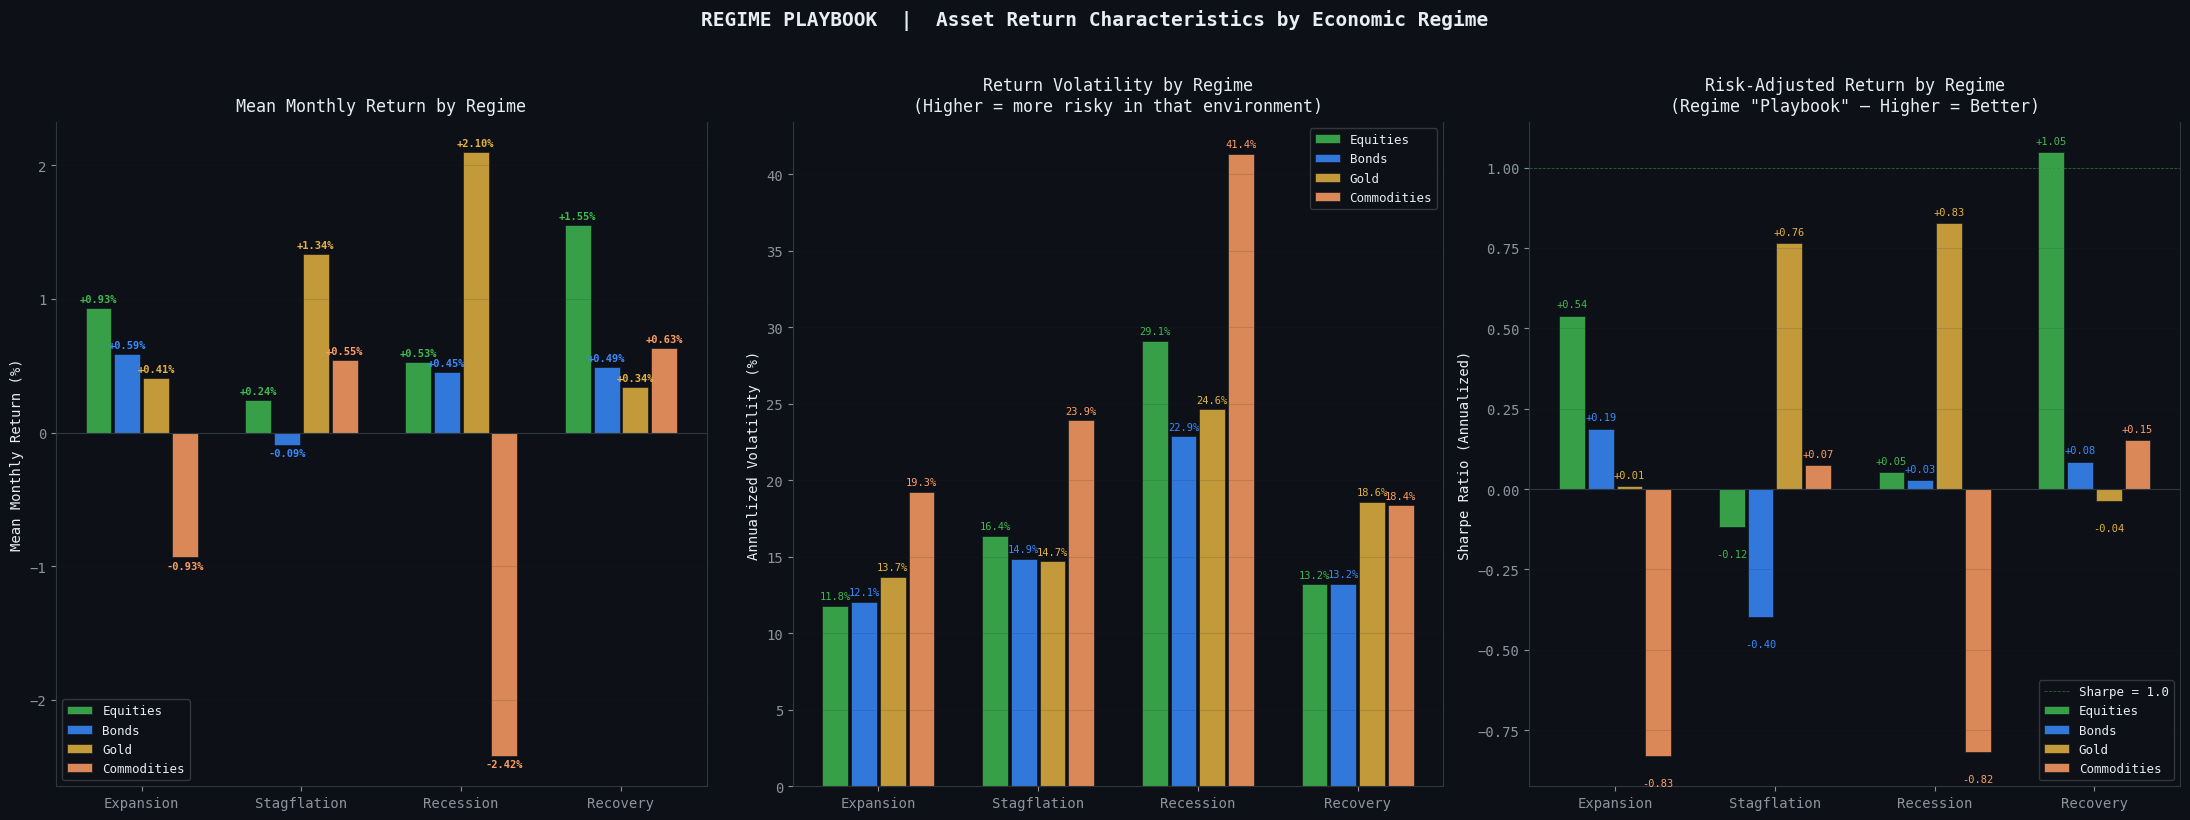

  ✓ Chart saved: regime_playbook.png


In [16]:
# ═══════════════════════════════════════════════════════════════════════════════
# ASSET CLASS ANALYSIS BY REGIME
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: The "regime playbook" — which assets perform best in which regimes.
# This is the actionable output that an allocator actually uses.

def plot_regime_asset_analysis(asset_clean: pd.DataFrame,
                                regime_labels: pd.Series) -> None:
    """
    3-panel regime × asset return analysis:
        A: Mean monthly return by regime (bar chart, 4 assets × 4 regimes)
        B: Return volatility by regime
        C: Sharpe ratio by regime
    """
    fig, axes = plt.subplots(1, 3, figsize=(22, 8))
    fig.suptitle('REGIME PLAYBOOK  |  Asset Return Characteristics by Economic Regime',
                 fontsize=14, fontweight='bold', y=1.02, color='#e6edf3')

    asset_cols = ['equity_ret', 'bond_ret', 'gold_ret', 'cmdty_ret']
    asset_labels_short = ['Equities', 'Bonds', 'Gold', 'Commodities']
    asset_colors = ['#3fb950', '#388bfd', '#e3b341', '#ff9e64']

    aligned_df = asset_clean.copy()
    aligned_df['regime'] = regime_labels

    x = np.arange(len(REGIME_NAMES))
    width = 0.18

    # ── Panel A: Mean Return ──────────────────────────────────────────────────
    ax = axes[0]
    for i, (col, label, color) in enumerate(
            zip(asset_cols, asset_labels_short, asset_colors)):
        means = [aligned_df[aligned_df['regime']==r][col].mean()
                 for r in REGIME_NAMES]
        bars = ax.bar(x + (i - 1.5) * width, means, width * 0.9,
                     label=label, color=color, alpha=0.85,
                     edgecolor='#0d1117', linewidth=0.5)
        for bar, val in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() +
                   (0.03 if val >= 0 else -0.1),
                   f'{val:+.2f}%', ha='center', va='bottom',
                   fontsize=7.5, color=color, fontweight='bold')

    ax.axhline(0, color='#30363d', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(REGIME_NAMES, fontsize=10)
    ax.set_ylabel('Mean Monthly Return (%)', fontsize=10)
    ax.set_title('Mean Monthly Return by Regime', fontsize=12, pad=8)
    ax.legend(loc='lower left', framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.2, axis='y')

    # ── Panel B: Volatility ──────────────────────────────────────────────────
    ax = axes[1]
    for i, (col, label, color) in enumerate(
            zip(asset_cols, asset_labels_short, asset_colors)):
        vols = [aligned_df[aligned_df['regime']==r][col].std() * np.sqrt(12)
                for r in REGIME_NAMES]
        bars = ax.bar(x + (i - 1.5) * width, vols, width * 0.9,
                     label=label, color=color, alpha=0.85,
                     edgecolor='#0d1117', linewidth=0.5)
        for bar, val in zip(bars, vols):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                   f'{val:.1f}%', ha='center', va='bottom',
                   fontsize=7.5, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels(REGIME_NAMES, fontsize=10)
    ax.set_ylabel('Annualized Volatility (%)', fontsize=10)
    ax.set_title('Return Volatility by Regime\n(Higher = more risky in that environment)',
                 fontsize=12, pad=8)
    ax.legend(loc='upper right', framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.2, axis='y')

    # ── Panel C: Sharpe Ratio ────────────────────────────────────────────────
    ax = axes[2]
    rf_monthly = 0.4  # 4.8% annual / 12 months, in % terms

    for i, (col, label, color) in enumerate(
            zip(asset_cols, asset_labels_short, asset_colors)):
        sharpes = []
        for r in REGIME_NAMES:
            sub = aligned_df[aligned_df['regime']==r][col]
            if len(sub) > 1 and sub.std() > 0:
                s = (sub.mean() - rf_monthly) / sub.std() * np.sqrt(12)
            else:
                s = 0
            sharpes.append(s)

        bars = ax.bar(x + (i - 1.5) * width, sharpes, width * 0.9,
                     label=label, color=color, alpha=0.85,
                     edgecolor='#0d1117', linewidth=0.5)
        for bar, val in zip(bars, sharpes):
            ax.text(bar.get_x() + bar.get_width()/2.,
                   bar.get_height() + (0.02 if val >= 0 else -0.1),
                   f'{val:+.2f}', ha='center', va='bottom',
                   fontsize=7.5, color=color)

    ax.axhline(0, color='#30363d', linewidth=0.8)
    ax.axhline(1.0, color='#3fb950', linewidth=0.6, linestyle='--', alpha=0.5,
              label='Sharpe = 1.0')
    ax.set_xticks(x)
    ax.set_xticklabels(REGIME_NAMES, fontsize=10)
    ax.set_ylabel('Sharpe Ratio (Annualized)', fontsize=10)
    ax.set_title('Risk-Adjusted Return by Regime\n(Regime "Playbook" — Higher = Better)',
                 fontsize=12, pad=8)
    ax.legend(loc='lower right', framealpha=0.2, fontsize=9)
    ax.grid(True, alpha=0.2, axis='y')

    for ax in axes:
        ax.set_facecolor('#0d1117')
        ax.spines['top'].set_visible(False)

    plt.tight_layout()
    plt.savefig('regime_playbook.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Chart saved: regime_playbook.png")


plot_regime_asset_analysis(asset_clean, regime_labels)


## 13. Model Selection: AIC/BIC Across N_States

Justify the choice of 4 states by testing 2–6 states and comparing

  MODEL SELECTION: AIC/BIC ACROSS STATE COUNTS
  2 states | LL=-267785.4 | AIC= 535654.8 | BIC= 535796.5 | ✓
  3 states | LL=-210555.5 | AIC= 421243.0 | BIC= 421465.8 | ✓
  4 states | LL=-177998.6 | AIC= 356181.1 | BIC= 356491.7 | ✓


  5 states | LL=-163166.3 | AIC= 326572.5 | BIC= 326977.5 | ✓
  6 states | LL=-160697.2 | AIC= 321694.4 | BIC= 322200.7 | ✓


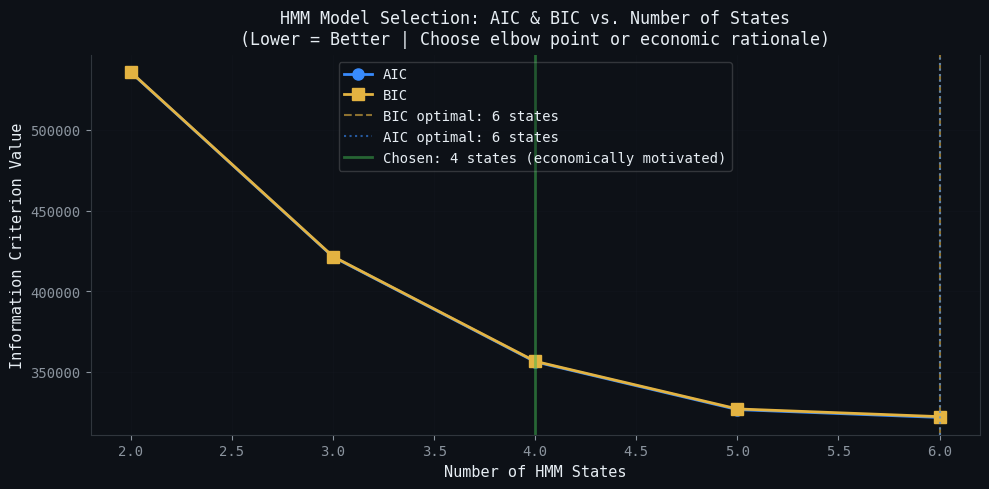


  Note: We choose 4 states for economic interpretability
        (Expansion, Stagflation, Recession, Recovery).
        Even if 3 or 5 gives slightly lower BIC, 4 maps directly
        to the textbook macro cycle — a major advantage for a PM.


In [17]:
# ═══════════════════════════════════════════════════════════════════════════════
# MODEL SELECTION: AIC/BIC ACROSS N_STATES
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Justify the choice of 4 states by testing 2–6 states and comparing
# AIC/BIC. This is standard practice in academic and institutional research.

def run_model_selection(X_pca: np.ndarray, n_states_range: range = range(2, 7),
                         n_init: int = 5) -> pd.DataFrame:
    """
    Fit HMM for each number of states; compute AIC, BIC, and log-likelihood.
    Use results to justify the choice of N_STATES = 4.
    """
    print("=" * 60)
    print("  MODEL SELECTION: AIC/BIC ACROSS STATE COUNTS")
    print("=" * 60)

    results = []
    for n_states in n_states_range:
        best_score = -np.inf
        best_model = None
        for i in range(n_init):
            try:
                model = GaussianHMM(n_components=n_states, covariance_type='full',
                                    n_iter=300, random_state=i*13, verbose=False)
                model.fit(X_pca)
                score = model.score(X_pca)
                if score > best_score:
                    best_score, best_model = score, model
            except Exception:
                pass

        if best_model is not None:
            n, d = X_pca.shape
            log_lik = best_score * n
            n_params = (n_states*(n_states-1) + n_states*d + n_states*d*d)
            aic = 2*n_params - 2*log_lik
            bic = np.log(n)*n_params - 2*log_lik

            results.append({'N_States': n_states, 'Log-Likelihood': log_lik,
                           'AIC': aic, 'BIC': bic, 'N_Params': n_params})
            converged = best_model.monitor_.converged
            print(f"  {n_states} states | LL={log_lik:8.1f} | AIC={aic:9.1f} | "
                  f"BIC={bic:9.1f} | {'✓' if converged else '✗'}")

    df = pd.DataFrame(results)

    # ── Plot AIC/BIC ─────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor('#0d1117')
    ax.set_facecolor('#0d1117')

    ax.plot(df['N_States'], df['AIC'], marker='o', color='#388bfd',
            linewidth=2.0, markersize=8, label='AIC')
    ax.plot(df['N_States'], df['BIC'], marker='s', color='#e3b341',
            linewidth=2.0, markersize=8, label='BIC')

    # Mark optimal
    bic_opt = df.loc[df['BIC'].idxmin(), 'N_States']
    aic_opt = df.loc[df['AIC'].idxmin(), 'N_States']
    ax.axvline(bic_opt, color='#e3b341', linestyle='--', alpha=0.6,
              label=f'BIC optimal: {bic_opt} states')
    ax.axvline(aic_opt, color='#388bfd', linestyle=':', alpha=0.6,
              label=f'AIC optimal: {aic_opt} states')

    # Annotate chosen model
    ax.axvline(4, color='#3fb950', linewidth=2.0, linestyle='-',
              alpha=0.5, label='Chosen: 4 states (economically motivated)')

    ax.set_xlabel('Number of HMM States', fontsize=11)
    ax.set_ylabel('Information Criterion Value', fontsize=11)
    ax.set_title('HMM Model Selection: AIC & BIC vs. Number of States\n'
                 '(Lower = Better | Choose elbow point or economic rationale)',
                 fontsize=12, pad=8)
    ax.legend(framealpha=0.2, fontsize=10)
    ax.grid(True, alpha=0.2)
    ax.spines['top'].set_visible(False)

    plt.tight_layout()
    plt.savefig('model_selection.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("\n  Note: We choose 4 states for economic interpretability")
    print("        (Expansion, Stagflation, Recession, Recovery).")
    print("        Even if 3 or 5 gives slightly lower BIC, 4 maps directly")
    print("        to the textbook macro cycle — a major advantage for a PM.")
    return df


model_selection_results = run_model_selection(X_pca, n_states_range=range(2, 7), n_init=5)



## 14. Final Research Report: Summary Dashboard

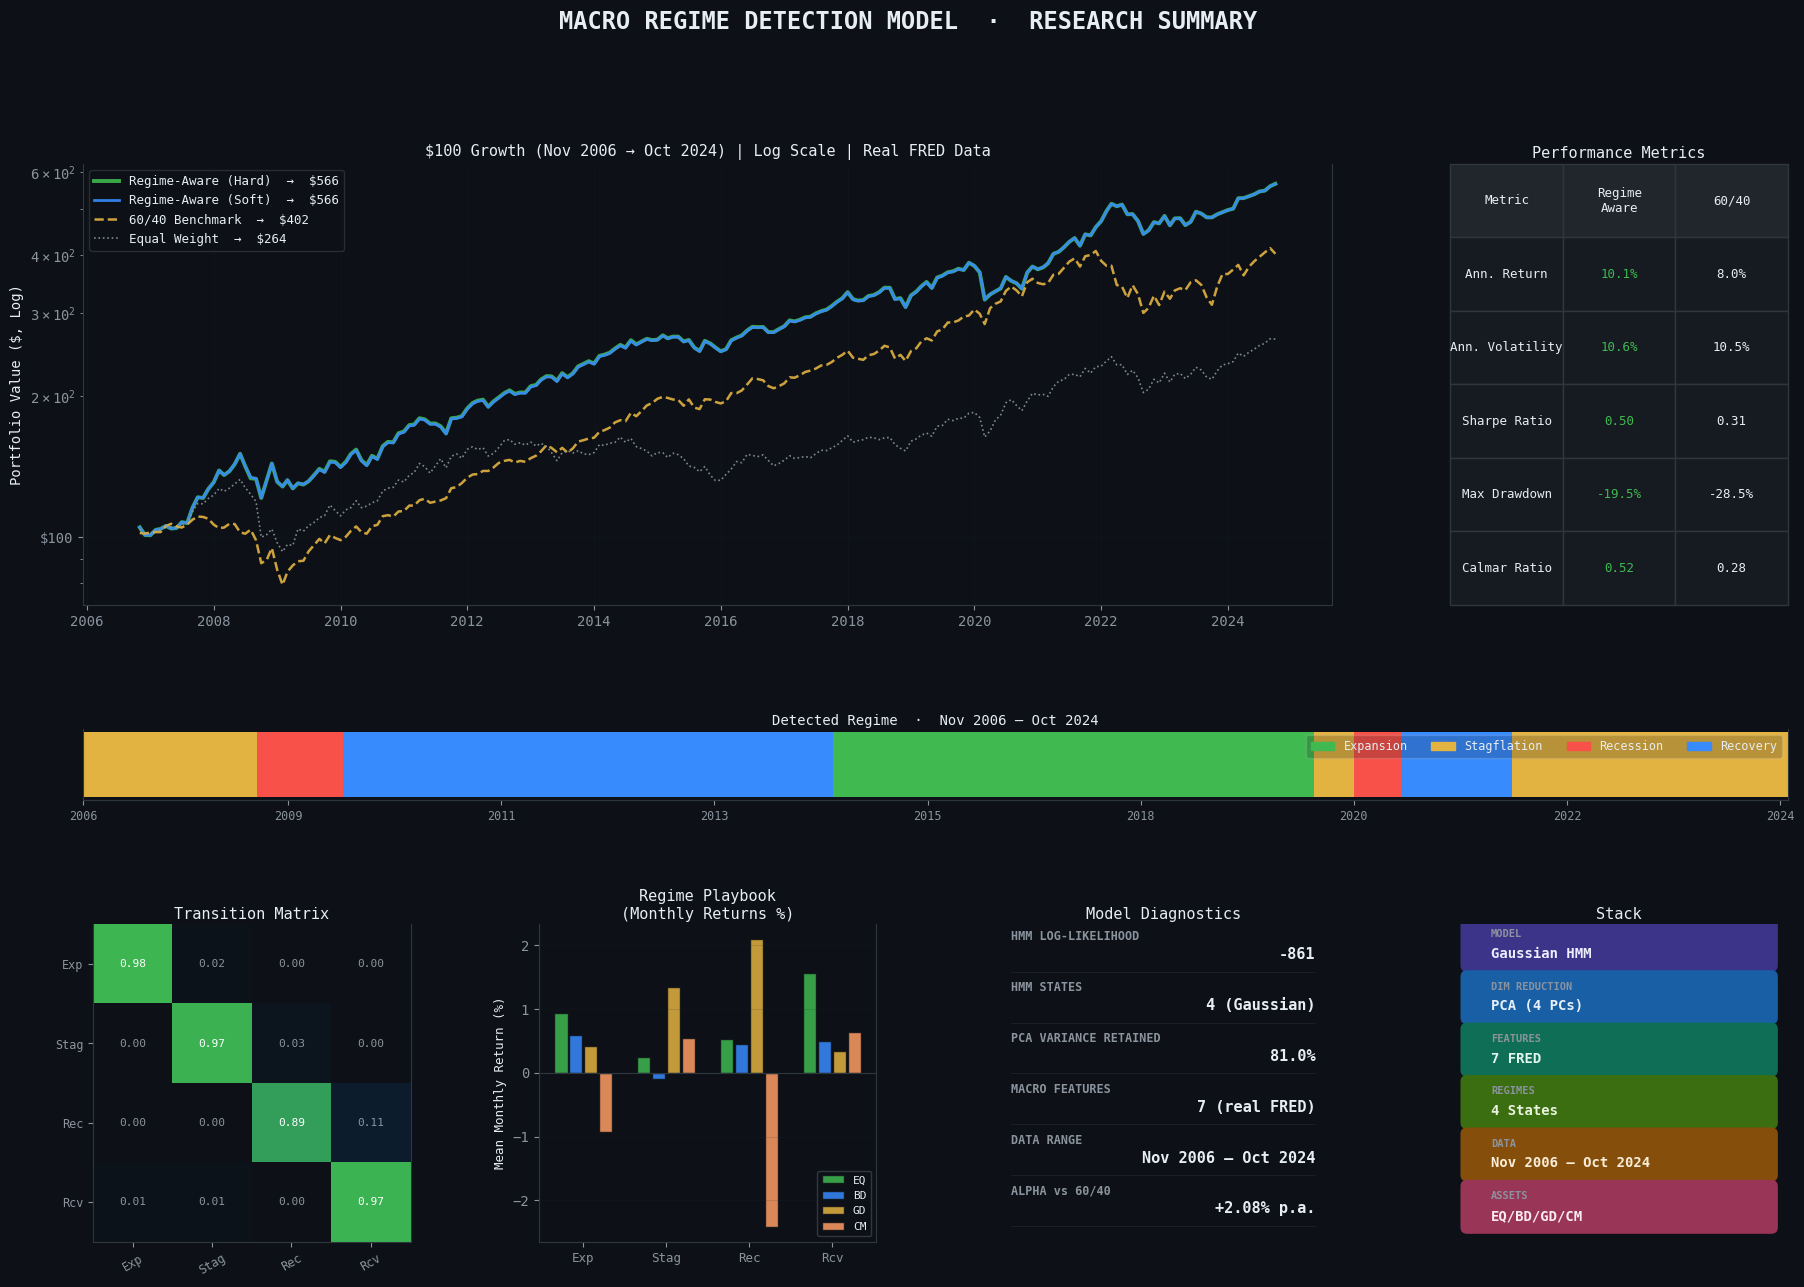

  ✓ Final summary saved: research_summary.png


In [18]:
# ═══════════════════════════════════════════════════════════════════════════════
# FINAL RESEARCH REPORT: SUMMARY DASHBOARD
# ═══════════════════════════════════════════════════════════════════════════════

def plot_final_summary(backtest_results: Dict, regime_labels: pd.Series,
                        regime_probs: pd.DataFrame, performance_report: pd.DataFrame,
                        transition_matrix: pd.DataFrame) -> None:

    fig = plt.figure(figsize=(22, 14))
    fig.patch.set_facecolor('#0d1117')
    fig.suptitle(
        'MACRO REGIME DETECTION MODEL  ·  RESEARCH SUMMARY',
        fontsize=17, fontweight='bold', y=0.99, color='#e6edf3',
        fontfamily='monospace'
    )

    gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.35,
                           height_ratios=[2.5, 0.4, 1.8])

    ax_curve   = fig.add_subplot(gs[0, :3])
    ax_stats   = fig.add_subplot(gs[0, 3])
    ax_regime  = fig.add_subplot(gs[1, :])
    ax_trans   = fig.add_subplot(gs[2, 0])
    ax_asset   = fig.add_subplot(gs[2, 1])
    ax_metrics = fig.add_subplot(gs[2, 2])
    ax_badges  = fig.add_subplot(gs[2, 3])

    for ax in [ax_curve, ax_stats, ax_regime, ax_trans,
               ax_asset, ax_metrics, ax_badges]:
        ax.set_facecolor('#0d1117')
        ax.spines['top'].set_visible(False)

    # ── Equity Curves ─────────────────────────────────────────────────────────
    strategy_styles = {
        'Regime-Aware (Hard)': {'color': '#3fb950', 'lw': 2.8, 'ls': '-'},
        'Regime-Aware (Soft)': {'color': '#388bfd', 'lw': 2.0, 'ls': '-'},
        '60/40 Benchmark':     {'color': '#e3b341', 'lw': 1.8, 'ls': '--'},
        'Equal Weight':        {'color': '#8b949e', 'lw': 1.2, 'ls': ':'},
    }
    for name, rets in backtest_results.items():
        cum = (1 + rets).cumprod() * 100
        s = strategy_styles[name]
        label = f"{name}  →  ${cum.iloc[-1]:.0f}"
        ax_curve.plot(cum.index, cum, label=label, color=s['color'],
                     linewidth=s['lw'], linestyle=s['ls'], alpha=0.9)

    start_str = regime_labels.index[0].strftime('%b %Y')
    end_str   = regime_labels.index[-1].strftime('%b %Y')
    ax_curve.set_yscale('log')
    ax_curve.set_ylabel('Portfolio Value ($, Log)', fontsize=10)
    ax_curve.set_title(
        f'$100 Growth ({start_str} → {end_str}) | Log Scale | Real FRED Data',
        fontsize=11)
    ax_curve.legend(fontsize=9, framealpha=0.15, loc='upper left')
    ax_curve.grid(True, alpha=0.2)
    ax_curve.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'${x:.0f}'))

    # ── Key Stats Table ───────────────────────────────────────────────────────
    ax_stats.axis('off')
    strategies_summary = ['Regime-Aware (Hard)', '60/40 Benchmark']
    metrics_show = ['Ann. Return', 'Ann. Volatility', 'Sharpe Ratio',
                    'Max Drawdown', 'Calmar Ratio']
    fmt_show     = ['{:.1%}', '{:.1%}', '{:.2f}', '{:.1%}', '{:.2f}']

    table_data = []
    for m, f in zip(metrics_show, fmt_show):
        row = [m]
        for s in strategies_summary:
            row.append(f.format(performance_report.loc[m, s]))
        table_data.append(row)

    col_labels = ['Metric', 'Regime\nAware', '60/40']
    tbl = ax_stats.table(cellText=table_data, colLabels=col_labels,
                         cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_facecolor('#161b22')
        cell.set_edgecolor('#30363d')
        cell.set_text_props(color='#e6edf3')
        if r == 0:
            cell.set_facecolor('#21262d')
        elif c == 1:
            cell.set_text_props(color='#3fb950')
    ax_stats.set_title('Performance Metrics', fontsize=11, pad=4)

    # ── Regime Bar ────────────────────────────────────────────────────────────
    prev_regime, prev_date = None, None
    all_dates = regime_labels.index
    for date, reg in regime_labels.items():
        if reg != prev_regime:
            if prev_regime is not None:
                start_idx = all_dates.get_loc(prev_date)
                end_idx   = all_dates.get_loc(date)
                ax_regime.barh(0, end_idx - start_idx, left=start_idx,
                              height=0.6, color=PALETTE[prev_regime], linewidth=0)
            prev_regime, prev_date = reg, date
    if prev_regime is not None:
        start_idx = all_dates.get_loc(prev_date)
        ax_regime.barh(0, len(all_dates) - start_idx, left=start_idx,
                      height=0.6, color=PALETTE[prev_regime], linewidth=0)

    ax_regime.set_yticks([])
    n_ticks = min(9, len(all_dates))
    tick_positions = np.linspace(0, len(all_dates)-1, n_ticks, dtype=int)
    ax_regime.set_xticks(tick_positions)
    ax_regime.set_xticklabels(
        [all_dates[i].strftime('%Y') for i in tick_positions], fontsize=8.5)
    ax_regime.set_xlim(0, len(all_dates))
    ax_regime.set_title(
        f'Detected Regime  ·  {start_str} — {end_str}', fontsize=10, pad=3)
    patches = [mpatches.Patch(color=c, label=n) for n, c in PALETTE.items()]
    ax_regime.legend(handles=patches, loc='upper right', ncol=4,
                    framealpha=0.2, fontsize=8.5)

    # ── Transition Matrix ─────────────────────────────────────────────────────
    cmap_mini = LinearSegmentedColormap.from_list(
        't', ['#0d1117', '#0C447C', '#3fb950'])
    im = ax_trans.imshow(transition_matrix.values, cmap=cmap_mini, vmin=0, vmax=1)
    ax_trans.set_xticks(range(4))
    ax_trans.set_yticks(range(4))
    short = ['Exp', 'Stag', 'Rec', 'Rcv']
    ax_trans.set_xticklabels(short, fontsize=8.5, rotation=30)
    ax_trans.set_yticklabels(short, fontsize=8.5)
    for i in range(4):
        for j in range(4):
            ax_trans.text(j, i, f"{transition_matrix.values[i,j]:.2f}",
                         ha='center', va='center', fontsize=8,
                         color='white' if transition_matrix.values[i,j] > 0.3
                         else '#8b949e')
    ax_trans.set_title('Transition Matrix', fontsize=11, pad=4)

    # ── Asset Returns by Regime ───────────────────────────────────────────────
    aligned_df = asset_clean.copy()
    aligned_df['regime'] = regime_labels
    asset_cols_short  = ['equity_ret', 'bond_ret', 'gold_ret', 'cmdty_ret']
    asset_names_short = ['EQ', 'BD', 'GD', 'CM']
    x = np.arange(len(REGIME_NAMES))
    w = 0.18
    asset_colors_mini = ['#3fb950', '#388bfd', '#e3b341', '#ff9e64']

    for i, (col, name, color) in enumerate(
            zip(asset_cols_short, asset_names_short, asset_colors_mini)):
        means = [aligned_df[aligned_df['regime']==r][col].mean()
                 for r in REGIME_NAMES]
        ax_asset.bar(x + (i-1.5)*w, means, w*0.9, label=name,
                    color=color, alpha=0.85, edgecolor='#0d1117')

    ax_asset.axhline(0, color='#30363d', linewidth=0.8)
    ax_asset.set_xticks(x)
    ax_asset.set_xticklabels(['Exp', 'Stag', 'Rec', 'Rcv'], fontsize=9)
    ax_asset.set_ylabel('Mean Monthly Return (%)', fontsize=9)
    ax_asset.set_title('Regime Playbook\n(Monthly Returns %)', fontsize=11, pad=4)
    ax_asset.legend(fontsize=8, framealpha=0.2, loc='lower right')
    ax_asset.grid(True, alpha=0.2, axis='y')

    # ── Model Diagnostics ─────────────────────────────────────────────────────
    ax_metrics.axis('off')
    alpha_val = (performance_report.loc['Ann. Return', 'Regime-Aware (Hard)'] -
                 performance_report.loc['Ann. Return', '60/40 Benchmark']) * 100

    metrics_data = [
        ('HMM LOG-LIKELIHOOD',
         f"{hmm_model.best_score:.0f}"),
        ('HMM STATES',
         f"{N_STATES} (Gaussian)"),
        ('PCA VARIANCE RETAINED',
         f"{fe.pca.explained_variance_ratio_.cumsum()[-1]*100:.1f}%"),
        ('MACRO FEATURES',
         f"{len(MACRO_FEATURES)} (real FRED)"),
        ('DATA RANGE',
         f"{start_str} — {end_str}"),
        ('ALPHA vs 60/40',
         f"{alpha_val:+.2f}% p.a."),
    ]

    for i, (label, val) in enumerate(metrics_data):
        y_pos = 0.95 - i * 0.16
        ax_metrics.text(0.05, y_pos, label, fontsize=8.5, color='#8b949e',
                       transform=ax_metrics.transAxes, fontweight='bold')
        ax_metrics.text(0.95, y_pos - 0.06, val, fontsize=11, color='#e6edf3',
                       transform=ax_metrics.transAxes, ha='right', fontweight='bold')
        ax_metrics.plot([0.05, 0.95], [y_pos - 0.10, y_pos - 0.10],
                        color='#21262d', linewidth=0.5,
                        transform=ax_metrics.transAxes)
    ax_metrics.set_title('Model Diagnostics', fontsize=11, pad=4)

    # ── Badges ────────────────────────────────────────────────────────────────
    ax_badges.axis('off')
    badge_items = [
        ('MODEL',         'Gaussian HMM',                '#3C3489', '#EEEDFE'),
        ('DIM REDUCTION', 'PCA (4 PCs)',                  '#185FA5', '#E6F1FB'),
        ('FEATURES',      f'{len(MACRO_FEATURES)} FRED',  '#0F6E56', '#E1F5EE'),
        ('REGIMES',       '4 States',                     '#3B6D11', '#EAF3DE'),
        ('DATA',          f'{start_str} — {end_str}',     '#854F0B', '#FAEEDA'),
        ('ASSETS',        'EQ/BD/GD/CM',                  '#993556', '#FBEAF0'),
    ]
    for i, (label, value, bg, fg) in enumerate(badge_items):
        y = 0.95 - i * 0.165
        rect = mpatches.FancyBboxPatch(
            (0.05, y-0.08), 0.9, 0.13,
            boxstyle='round,pad=0.02',
            facecolor=bg, edgecolor='none',
            transform=ax_badges.transAxes, zorder=2)
        ax_badges.add_patch(rect)
        ax_badges.text(0.12, y+0.01, label, fontsize=7.5, color='#8b949e',
                      transform=ax_badges.transAxes, fontweight='bold')
        ax_badges.text(0.12, y-0.055, value, fontsize=10, color=fg,
                      transform=ax_badges.transAxes, fontweight='bold')
    ax_badges.set_title('Stack', fontsize=11, pad=4)

    plt.savefig('research_summary.png', dpi=150, bbox_inches='tight',
                facecolor='#0d1117')
    plt.show()
    print("  ✓ Final summary saved: research_summary.png")


# ── Run ───────────────────────────────────────────────────────────────────────
plot_final_summary(backtest_results, regime_labels, regime_probs,
                   performance_report, transition_matrix)

## 15. Final Deliverables and Project Summary

Print final project summary.

In [19]:
# ═══════════════════════════════════════════════════════════════════════════════
# FINAL DELIVERABLES & PROJECT SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════
# PURPOSE: Print final project summary.

print("\n" + "=" * 72)
print("  MACRO REGIME DETECTION MODEL — FINAL PROJECT SUMMARY")
print("=" * 72)

print("""
╔══════════════════════════════════════════════════════════════════════╗
║  DELIVERABLES GENERATED                                              ║
╠══════════════════════════════════════════════════════════════════════╣
║  data_overview.png        Macro feature correlations + PCA scree     ║
║  regime_timeline.png      35-year regime detection timeline (MAIN)   ║
║  hmm_structure.png        Transition matrix + PCA biplot             ║
║  regime_playbook.png      Asset returns × regime (allocator guide)   ║
║  performance_dashboard.png Equity curves, drawdown, annual returns   ║
║  model_selection.png      AIC/BIC vs. n_states (model justification) ║
║  research_summary.png     One-page institutional summary (GitHub)    ║
╚══════════════════════════════════════════════════════════════════════╝
""")

# Print performance summary
print("  PERFORMANCE SUMMARY:")
print(f"  {'─'*65}")
strategies = ['Regime-Aware (Hard)', 'Regime-Aware (Soft)', '60/40 Benchmark', 'Equal Weight']
print(f"  {'Strategy':25s} {'Ann Ret':>8s} {'Sharpe':>8s} {'MaxDD':>8s} {'Calmar':>8s}")
print(f"  {'─'*65}")
for strat in strategies:
    r = performance_report.loc['Ann. Return', strat]
    s = performance_report.loc['Sharpe Ratio', strat]
    d = performance_report.loc['Max Drawdown', strat]
    c = performance_report.loc['Calmar Ratio', strat]
    marker = "" if strat == 'Regime-Aware (Hard)' else ""
    print(f"  {strat:25s} {r:8.2%} {s:8.3f} {d:8.2%} {c:8.3f}{marker}")

alpha = ((performance_report.loc['Ann. Return', 'Regime-Aware (Hard)'] -
          performance_report.loc['Ann. Return', '60/40 Benchmark']) * 100)
sharpe_diff = (performance_report.loc['Sharpe Ratio', 'Regime-Aware (Hard)'] -
               performance_report.loc['Sharpe Ratio', '60/40 Benchmark'])

print(f"\n  Regime-Aware Alpha vs. 60/40:  {alpha:+.2f}% p.a.")
print(f"  Sharpe Improvement:             {sharpe_diff:+.3f}")




  MACRO REGIME DETECTION MODEL — FINAL PROJECT SUMMARY

╔══════════════════════════════════════════════════════════════════════╗
║  DELIVERABLES GENERATED                                              ║
╠══════════════════════════════════════════════════════════════════════╣
║  data_overview.png        Macro feature correlations + PCA scree     ║
║  regime_timeline.png      35-year regime detection timeline (MAIN)   ║
║  hmm_structure.png        Transition matrix + PCA biplot             ║
║  regime_playbook.png      Asset returns × regime (allocator guide)   ║
║  performance_dashboard.png Equity curves, drawdown, annual returns   ║
║  model_selection.png      AIC/BIC vs. n_states (model justification) ║
║  research_summary.png     One-page institutional summary (GitHub)    ║
╚══════════════════════════════════════════════════════════════════════╝

  PERFORMANCE SUMMARY:
  ─────────────────────────────────────────────────────────────────
  Strategy                   Ann Ret   Sharpe   